# TAM400 VPN Traffic Classification
**Shucayb AHmed Said and Ayub Ali Barre · Group 17**

## Part 1 — Introduction and dataset
We compare majority-class, linear and Random Forest classifiers for VPN versus NonVPN network flows. We then investigate whether controlled regularization offers a useful trade-off between validation performance and the training–validation gap.

Run this entire notebook in one Google Colab CPU runtime using **Runtime > Run all**. All training, screening, tables and figures are computed here. No saved model or external results file is required. The saved outputs document an actual execution. The full experiment includes several hundred forest fits and can take a substantial amount of CPU time.

The dataset is [ISCXVPN2016 from the Canadian Institute for Cybersecurity](https://www.unb.ca/cic/datasets/vpn.html). We use the same pinned public ARFF mirror as earlier project versions. Its hash verifies that the input stays unchanged; it does not independently authenticate the mirror against the official archive. This is classification of recorded flow measurements, not a live VPN-switch detector.

### Final evaluation update
RF-206 was selected before this update. Its exact configuration is frozen. Running all cells reproduces the existing training-only comparisons, then evaluates that same model on the existing held-out partition. The update adds no hyperparameter candidates, threshold search or test-based selection. Median imputation is fitted only on the training partition. The reported test results are a **Reused development-test evaluation — not an independent untouched test.**


### Reproducible software
The reference execution used Python 3.12 and the package versions below. This cell installs those versions only when needed. Run it before importing the packages in a fresh runtime. If Colab reports that previously imported packages need restarting, restart the runtime and choose Run all. Small platform differences remain possible.

In [1]:
import importlib.metadata
import subprocess
import sys
versions = {"scikit-learn":"1.6.1", "pandas":"2.2.3", "numpy":"2.1.3", "matplotlib":"3.10.7", "scipy":"1.14.1"}
needed = []
for package, version in versions.items():
    try:
        installed = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        needed.append(f"{package}=={version}")
if needed:
    subprocess.check_call([sys.executable,"-m","pip","install","-q",*needed])
from pathlib import Path
from io import StringIO
from urllib.request import urlretrieve
import hashlib, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, learning_curve
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.inspection import permutation_importance
SEED = 42
OUT = Path("advanced_results")
OUT.mkdir(exist_ok=True)
print("Python:",sys.version.split()[0])
print({name:importlib.metadata.version(name) for name in versions})

Python: 3.12.14
{'scikit-learn': '1.6.1', 'pandas': '2.2.3', 'numpy': '2.1.3', 'matplotlib': '3.10.7', 'scipy': '1.14.1'}


In [2]:
url = "https://raw.githubusercontent.com/shafwanur/thd-ss25-ml-project/b4488cf1022157a319d9ccdfa36f86cb940e2b80/data/15s.arff"
expected_hash = "8b12e8c0cd49f56af28cdaa7c2aa7795ee24de0b1bedf638280e00404f7c1563"
data_file = Path("15s.arff")
if not data_file.exists():
    urlretrieve(url, data_file)
assert hashlib.sha256(data_file.read_bytes()).hexdigest() == expected_hash, "Unexpected dataset file"

# Read the ARFF column names and then its data rows.
lines = data_file.read_text().splitlines()
columns = [line.split()[1] for line in lines if line.upper().startswith("@ATTRIBUTE")]
start = next(i for i, line in enumerate(lines) if line.upper().startswith("@DATA")) + 1
df = pd.read_csv(StringIO("\n".join(lines[start:])), names=columns)
print("Raw rows and columns:", df.shape)
display(df.head())

Raw rows and columns: (18758, 24)


,duration,total_fiat,total_biat,min_fiat,min_biat,max_fiat,max_biat,mean_fiat,mean_biat,flowPktsPerSecond,flowBytesPerSecond,min_flowiat,max_flowiat,mean_flowiat,std_flowiat,min_active,mean_active,max_active,std_active,min_idle,mean_idle,max_idle,std_idle,class1
0,9368711,16,4,1564818,1549373,190205.285714,203290.456522,389822.391917,370323.719754,10.353612,4802.688438,4,1523088,97590.739583,267600.198443,1871488,1.983656e+06,2195089,1.832197e+05,1234883,1420565.0,1523088,161096.539275,CHAT
1,7340238,18,4,1567554,1527893,165686.977273,186914.846154,317267.548742,304370.651301,11.580006,4340.186245,4,1517774,87383.785714,221462.862028,1491627,3.572433e+06,5653239,2.942704e+06,1131498,1324636.0,1517774,273138.379008,CHAT
2,4644225,29,15,1270547,1079974,165865.178571,195302.130435,329473.126261,300492.588227,11.412022,4161.512416,15,1079974,89312.019231,217475.425246,1758922,1.758922e+06,1758922,0.000000e+00,1079974,1079974.0,1079974,0.000000,CHAT
3,4978735,19,8,2492050,2457286,239543.250000,276596.388889,612435.304238,628339.573544,8.034169,3918.666087,8,2441990,127659.871795,436959.716436,1710925,2.382905e+06,3054885,9.503232e+05,1346073,1894031.5,2441990,774930.342317,CHAT
4,11838189,19,10,3094089,3093543,243766.500000,295954.725000,599721.781709,625632.703972,7.602514,2802.540152,10,3042717,133013.359551,436129.639296,1747431,2.400446e+06,3240696,6.232744e+05,1394455,1983227.0,3042717,725987.829075,CHAT


## Part 2 — Data preprocessing
NonVPN = 0 and VPN = 1. We keep the original nine numeric features. Negative measurements become missing values. We first retain one copy of each identical input/label row, then remove input vectors with conflicting labels. No outliers or difficult observations are removed to improve the scores.

**Limitation:** conflict cleaning uses labels before the split, so the retained dataset depends on labels across the full source. We preserve that workflow for comparability, but cannot claim the entire dataset construction was independent of held-out labels. Learned medians and scaling parameters are fitted within each training fold later.

The split remains stratified 80/20 with seed 42. The previous test partition is retained only to verify the split and exact input overlap. It is not scored or used to choose any setting in this revision.

In [3]:
features = ["duration", "flowPktsPerSecond", "flowBytesPerSecond",
            "min_flowiat", "max_flowiat", "mean_flowiat", "std_flowiat",
            "mean_active", "mean_idle"]
X = df[features].copy()
y = df["class1"].str.strip().str.upper().str.startswith("VPN-").astype(int).rename("vpn")

negative_cells = int((X < 0).sum().sum())
X[X < 0] = np.nan
clean = pd.concat([X, y], axis=1)
before_duplicates = len(clean)
clean = clean.drop_duplicates()  # Keep one row when both inputs and label are identical.
identical_rows_removed = before_duplicates - len(clean)
before_conflicts = len(clean)
clean = clean.drop_duplicates(subset=features, keep=False)
conflicting_rows_removed = before_conflicts - len(clean)  # Remove conflicting labels.
removed_rows = len(df) - len(clean)
X, y = clean[features], clean["vpn"]

print("Invalid negative cells replaced with missing values:", negative_cells)
print("Duplicate or conflicting rows removed:", removed_rows)
print("Clean rows:", len(clean))
print("Number of input features:", X.shape[1])
FEATURES = features.copy()
assert len(df)==18758 and len(clean)==17979
assert identical_rows_removed==725 and conflicting_rows_removed==54
print("Identical rows removed:",identical_rows_removed,"Conflicting rows removed:",conflicting_rows_removed)

Invalid negative cells replaced with missing values: 1240
Duplicate or conflicting rows removed: 779
Clean rows: 17979
Number of input features: 9
Identical rows removed: 725 Conflicting rows removed: 54


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
print("Training flows:", len(X_train))
print("Test flows:", len(X_test))
print("Training class counts (0 = NonVPN, 1 = VPN):")
print(y_train.value_counts().sort_index())
assert len(X_train)==14383 and len(X_test)==3596
split_hash = hashlib.sha256(X_test.index.to_numpy().tobytes()).hexdigest()
assert split_hash == "bbb0deef12ebaf2233e4c561f752c7ab8b0fc44f4b1de2073b4919e7812f064f"
train_hashes = pd.util.hash_pandas_object(X_train,index=False)
test_hashes = pd.util.hash_pandas_object(X_test,index=False)
exact_overlap = int(train_hashes.isin(test_hashes).sum())
assert exact_overlap == 0
print("Exact input overlap across the fixed split:",exact_overlap)
print("Held-out index SHA256:",split_hash)
data_counts = {"raw":len(df),"clean":len(clean),"train":len(X_train),"held_out":len(X_test),
    "identical_removed":identical_rows_removed,"conflicting_removed":conflicting_rows_removed,
    "negative_cells":negative_cells,"train_classes":y_train.value_counts().sort_index().to_dict()}

Training flows: 14383
Test flows: 3596
Training class counts (0 = NonVPN, 1 = VPN):
vpn
0    6927
1    7456
Name: count, dtype: int64
Exact input overlap across the fixed split: 0
Held-out index SHA256: bbb0deef12ebaf2233e4c561f752c7ab8b0fc44f4b1de2073b4919e7812f064f


## Part 3 — Exploratory Data Analysis
These summaries use the training partition. Duration is stored in microseconds; divide by one million for seconds in the plots only. The full-range histogram keeps the long tail visible, and the 0–15 second panel reveals the main concentration. Longer flows remain in the model data.

Pearson correlation describes a linear association with the binary label. Weak correlations do not rule out nonlinear or joint predictive information, so we retain all nine features.

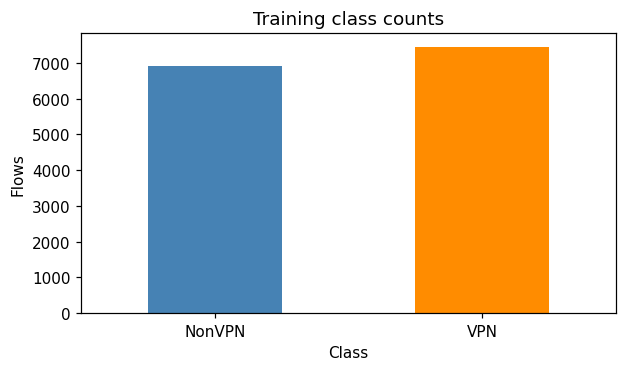

Training duration in seconds:


count    14383.000
mean        10.178
std         14.860
min          0.000
25%          0.692
50%         11.850
75%         14.960
95%         14.999
max        601.405
Name: duration, dtype: float64

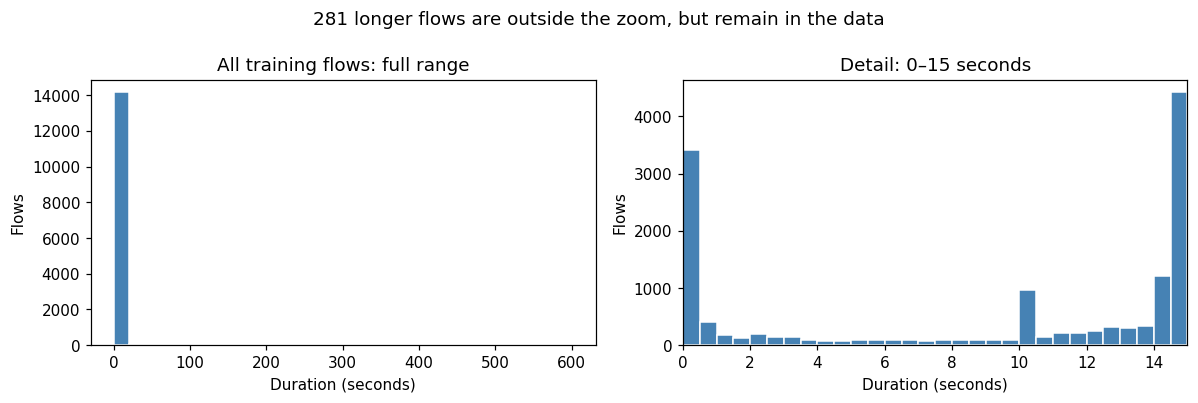

,Feature,Pearson correlation with VPN
0,mean_flowiat,0.0532
1,min_flowiat,0.0378
2,std_flowiat,0.0050
3,flowPktsPerSecond,0.0007
4,mean_active,-0.0077
5,max_flowiat,-0.0133
6,mean_idle,-0.0151
7,flowBytesPerSecond,-0.0347
8,duration,-0.0670


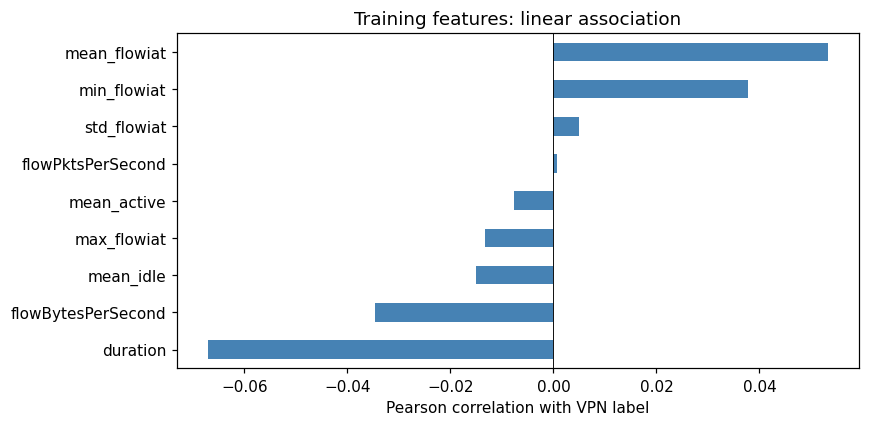

vpn,NonVPN median,VPN median
duration,1.321557e+07,1.007996e+07
flowPktsPerSecond,4.206934e+01,8.936986e+00
flowBytesPerSecond,1.030482e+04,1.579479e+03
min_flowiat,1.400000e+01,2.000000e+01
max_flowiat,1.731700e+05,9.224250e+05
mean_flowiat,2.560900e+04,1.381318e+05
std_flowiat,1.417966e+04,2.002908e+05
mean_active,0.000000e+00,0.000000e+00
mean_idle,0.000000e+00,0.000000e+00


,count,mean,std,min,50%,95%,99%,max,skew,missing
duration,14383.0,1.017835e+07,1.486012e+07,2.000000,1.185021e+07,1.499931e+07,6.039807e+07,601404954.0,15.156493,0
flowPktsPerSecond,14383.0,1.387963e+03,1.580018e+04,0.019762,1.211011e+01,3.287247e+03,2.726929e+04,1000000.0,35.273959,0
flowBytesPerSecond,14383.0,3.944237e+05,7.765804e+06,4.140041,2.787888e+03,7.214666e+05,4.870183e+06,617000000.0,64.455689,0
min_flowiat,14247.0,4.255472e+04,4.537535e+05,0.000000,1.800000e+01,1.735723e+05,3.683174e+05,18919905.0,28.358440,136
max_flowiat,14383.0,3.993675e+06,1.445045e+07,2.000000,5.575520e+05,1.006319e+07,5.995760e+07,600109654.0,17.538477,0
mean_flowiat,14383.0,4.905103e+05,1.450606e+06,2.000000,9.820169e+04,3.359097e+06,4.819222e+06,60700000.0,16.053346,0
std_flowiat,14383.0,1.063477e+06,3.610381e+06,0.000000,1.050539e+05,5.751039e+06,1.200000e+07,136000000.0,15.156730,0
mean_active,14383.0,3.762774e+06,1.409908e+07,0.000000,0.000000e+00,1.130000e+07,5.598000e+07,601000000.0,18.232194,0
mean_idle,14383.0,3.435109e+06,1.401056e+07,0.000000,0.000000e+00,1.000000e+07,5.581600e+07,600000000.0,18.537164,0


In [5]:
fig, ax = plt.subplots(figsize=(5.8, 3.5), num="class_counts")
y_train.value_counts().sort_index().plot.bar(ax=ax, color=["steelblue", "darkorange"])
ax.set(xticklabels=["NonVPN", "VPN"], xlabel="Class", ylabel="Flows", title="Training class counts")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

duration_seconds = X_train["duration"].dropna() / 1_000_000
duration_summary = duration_seconds.describe(percentiles=[0.25, 0.50, 0.75, 0.95])
print("Training duration in seconds:")
display(duration_summary.round(3))
outside_zoom = int((duration_seconds > 15).sum())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), num="duration_histogram")
axes[0].hist(duration_seconds, bins=30, color="steelblue", edgecolor="white")
axes[0].set(title="All training flows: full range", xlabel="Duration (seconds)", ylabel="Flows")
axes[1].hist(duration_seconds, bins=np.linspace(0, 15, 31), color="steelblue", edgecolor="white")
axes[1].set(title="Detail: 0–15 seconds", xlabel="Duration (seconds)", ylabel="Flows", xlim=(0, 15))
fig.suptitle(f"{outside_zoom:,} longer flows are outside the zoom, but remain in the data")
plt.tight_layout()
plt.show()

training_data = X_train.copy()
training_data["vpn"] = y_train
correlation_table = training_data.corr(numeric_only=True)["vpn"].drop("vpn").sort_values(ascending=False)
display(correlation_table.rename_axis("Feature").reset_index(name="Pearson correlation with VPN").round(4))
fig,ax=plt.subplots(figsize=(8,4),num="pearson_correlation")
correlation_table.sort_values().plot.barh(ax=ax,color="steelblue")
ax.set(xlabel="Pearson correlation with VPN label",title="Training features: linear association")
ax.axvline(0,color="black",lw=.6)
plt.tight_layout();plt.show()
class_medians=X_train.assign(vpn=y_train).groupby("vpn").median().T
feature_summary=X_train.describe(percentiles=[.5,.95,.99]).T
feature_summary["skew"]=X_train.skew()
feature_summary["missing"]=X_train.isna().sum()
display(class_medians.rename(columns={0:"NonVPN median",1:"VPN median"}))
display(feature_summary)
class_medians.to_csv(OUT/"class_medians.csv")
feature_summary.to_csv(OUT/"feature_summary.csv")

### Near-duplicate and capture-condition audit
Exact duplicates are gone, but very similar flows can remain. For a descriptive training-only check, we median-impute and scale each feature by its interquartile range, then measure the distance to the nearest other flow. A feature with zero interquartile range uses scale 1. These arbitrary distance thresholds count rows, not unique pairs, and cannot establish shared sessions.

This diagnostic transform is separate from classifier preprocessing and does not change any training data. The source has numeric traffic summaries and labels, without session, capture, IP or timestamp identifiers suitable for grouping. We therefore cannot fully test session leakage. Duration concentrations, zero-heavy activity features and class differences may partly encode capture conditions. Feature-importance checks later investigate model dependence, not causal VPN signatures.

In [6]:
audit_imputer=SimpleImputer(strategy="median")
audit_values=audit_imputer.fit_transform(X_train)
audit_scaled=RobustScaler().fit_transform(audit_values)
neighbors=NearestNeighbors(n_neighbors=2).fit(audit_scaled)
distances,indices=neighbors.kneighbors(audit_scaled)
nearest_distance=distances[:,1]
near_rows=[]
for threshold in [1e-6,1e-4,.01]:
    close=nearest_distance < threshold
    disagree=y_train.to_numpy()!=y_train.to_numpy()[indices[:,1]]
    near_rows.append({"Distance threshold":threshold,"Rows with close neighbor":int(close.sum()),
                      "Rows with differently labelled close neighbor":int((close & disagree).sum())})
near_duplicate_table=pd.DataFrame(near_rows)
display(near_duplicate_table)
print("Distance quantiles:",np.quantile(nearest_distance,[0,.01,.05,.1,.5,.9,1]))
print("Training duplicates after diagnostic median imputation:",pd.DataFrame(audit_values).duplicated().sum())
print("Infinite training values:",np.isinf(X_train.to_numpy()).sum())
near_duplicate_table.to_csv(OUT/"near_duplicate_audit.csv",index=False)

,Distance threshold,Rows with close neighbor,Rows with differently labelled close neighbor
0,0.000001,0,0
1,0.000100,38,0
2,0.010000,3872,73


Distance quantiles: [2.02677144e-05 1.80412485e-04 5.96268783e-04 1.24936411e-03
 8.71418713e-02 1.10989910e+00 7.92709740e+03]
Training duplicates after diagnostic median imputation: 0
Infinite training values: 0


## Part 4 — Initial model comparison and reference reproduction
DummyClassifier is the majority-class reference, SGDClassifier is the unchanged linear classifier, and RandomForestClassifier is the nonlinear algorithm. RF-206 and RF-210 are configurations of Random Forest, not separate algorithms.

All six models receive the same ten stratified folds, seed 42. Imputation and SGD scaling are fitted inside each training fold. Mean validation precision and recall are means across folds; they are not derived from the mean F1. We separately record full-training scores and mean fold-training scores.

First print every forest parameter and reproduce the saved full-training and ten-fold results for the four forest references. The historical constants below are verification targets, not scores supplied to model selection. No local results file is needed to run this notebook. Reference reproduction must pass before new configurations are fitted. Forest fits use one worker inside two-worker cross-validation to avoid nested parallelism; this does not change the model definition.

In [7]:
import json
import hashlib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, make_scorer

assert SEED == 42 and list(X_train.columns) == list(FEATURES) and len(FEATURES) == 9
OUT.mkdir(parents=True, exist_ok=True)
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
SCORING = {"f1": make_scorer(f1_score, zero_division=0), "accuracy": "accuracy",
           "precision": make_scorer(precision_score, zero_division=0),
           "recall": make_scorer(recall_score, zero_division=0)}
HISTORICAL_MARGIN = 0.005
EXPLORATORY_MARGIN = 0.010
STABILITY_SD_CAP = 0.015
RF_NAMES = ["Original Random Forest", "Previous Tuned Random Forest", "RF-206", "RF-210"]
HISTORICAL_REFERENCE = {'Original Random Forest': {'Training accuracy': 0.9999304734756309, 'Training VPN F1': 0.9999329354168064, 'CV F1 mean': 0.9016073691142055, 'CV F1 std': 0.007194482067345941, 'CV training F1': 1.0, 'CV training accuracy': 1.0, 'CV accuracy': 0.8971711927132213, 'CV F1 gap': 0.09839263088579453, 'fold_f1': [0.8881401617250674, 0.9068825910931174, 0.8950495049504951, 0.9095709570957096, 0.9048257372654156, 0.8942875902823375, 0.9063324538258575, 0.9116465863453815, 0.897742363877822, 0.901595744680851]}, 'Previous Tuned Random Forest': {'Training accuracy': 0.967322533546548, 'Training VPN F1': 0.9688163481953291, 'CV F1 mean': 0.8965464418120656, 'CV F1 std': 0.00898861283797206, 'CV training F1': 0.9698671601526702, 'CV training accuracy': 0.9684349828431689, 'CV accuracy': 0.8908443605076546, 'CV F1 gap': 0.07332071834060461, 'fold_f1': [0.8845897264843229, 0.9053606882859033, 0.8837516512549538, 0.9044834307992202, 0.8976063829787234, 0.8974526453298498, 0.9045751633986928, 0.9096945551128818, 0.8871493803000652, 0.8908007941760424]}, 'RF-206': {'Training accuracy': 0.937634707640965, 'Training VPN F1': 0.9406156901688183, 'CV F1 mean': 0.8938242141595077, 'CV F1 std': 0.00869329739999253, 'CV training F1': 0.9405163090383997, 'CV training accuracy': 0.9374879410418041, 'CV accuracy': 0.887784458570654, 'CV F1 gap': 0.04669209487889192, 'fold_f1': [0.8914057295136576, 0.9035667107001321, 0.8806855636123929, 0.9027237354085603, 0.8968253968253969, 0.8896146309601568, 0.9015003261578604, 0.9019867549668874, 0.8781127129750983, 0.8918205804749341]}, 'RF-210': {'Training accuracy': 0.925676145449489, 'Training VPN F1': 0.9292193603919751, 'CV F1 mean': 0.8904465288829441, 'CV F1 std': 0.007496091789292061, 'CV training F1': 0.9282377544324303, 'CV training accuracy': 0.9244942076895644, 'CV accuracy': 0.884169001615053, 'CV F1 gap': 0.03779122554948622, 'fold_f1': [0.8887408394403731, 0.8975545274289491, 0.8796296296296297, 0.8956578094620868, 0.8927152317880794, 0.8884540117416829, 0.8984375, 0.899009900990099, 0.8758169934640523, 0.8884488448844885]}}

original_model = Pipeline([("imputer", SimpleImputer(strategy="median")),
                           ("model", RandomForestClassifier(random_state=SEED))])
previous_model = clone(original_model).set_params(model__n_estimators=200, model__max_depth=16,
    model__min_samples_leaf=2, model__min_samples_split=2, model__max_features=6,
    model__max_samples=0.75, model__criterion="gini")
rf206_model = clone(original_model).set_params(model__n_estimators=200, model__max_depth=14,
    model__min_samples_leaf=4, model__min_samples_split=10, model__max_features=5,
    model__max_samples=0.70, model__criterion="entropy")
rf210_model = clone(rf206_model).set_params(model__n_estimators=500, model__min_samples_split=20)
reference_models = {
    "DummyClassifier": Pipeline([("imputer", SimpleImputer(strategy="median")),
                                 ("model", DummyClassifier(strategy="most_frequent"))]),
    "SGDClassifier": Pipeline([("imputer", SimpleImputer(strategy="median")),
                               ("scaler", StandardScaler()),
                               ("model", SGDClassifier(random_state=SEED))]),
    "Original Random Forest": original_model,
    "Previous Tuned Random Forest": previous_model,
    "RF-206": rf206_model, "RF-210": rf210_model}
for name in RF_NAMES:
    print(name, json.dumps(reference_models[name].named_steps["model"].get_params(), indent=2))

def row_hash(frame):
    return hashlib.sha256(np.asarray(frame.index, dtype=np.int64).tobytes()).hexdigest()

def save_checkpoint(name, rows, fold_frames):
    pd.DataFrame(rows).to_csv(OUT/(name+".csv"),index=False)
    if fold_frames:
        pd.concat(fold_frames,ignore_index=True).to_csv(OUT/(name+"_fold_scores.csv"),index=False)
    status={"phase":name,"completed_models":len(rows),"last_model":rows[-1]["Model"],
            "saved_utc":datetime.now(timezone.utc).isoformat()}
    (OUT/"checkpoint_status.json").write_text(json.dumps(status,indent=2))
    print("Checkpoint saved:",name,len(rows),"models",flush=True)

def forest_structure(fitted):
    estimator = fitted.named_steps["model"]
    if not isinstance(estimator, RandomForestClassifier):
        return {"nodes": np.nan, "leaves": np.nan, "depth": np.nan, "importance": None}
    return {"nodes": float(np.mean([tree.tree_.node_count for tree in estimator.estimators_])),
            "leaves": float(np.mean([tree.tree_.n_leaves for tree in estimator.estimators_])),
            "depth": float(np.mean([tree.tree_.max_depth for tree in estimator.estimators_])),
            "importance": estimator.feature_importances_.tolist()}

def evaluate_model(name, pipeline, X_part, y_part, cv, phase, full_fit=True):
    # Every estimated preprocessing parameter stays inside the pipeline.
    splits = list(cv.split(X_part, y_part))
    fit_pipeline = clone(pipeline)
    if isinstance(fit_pipeline.named_steps["model"], RandomForestClassifier):
        fit_pipeline.set_params(model__n_jobs=1)
    scores = cross_validate(fit_pipeline, X_part, y_part, cv=splits, scoring=SCORING,
        return_train_score=True, return_estimator=True, n_jobs=2, error_score="raise")
    fold_rows = []
    for fold, ((train_index, valid_index), fitted) in enumerate(zip(splits, scores["estimator"]), 1):
        fold_training_data = X_part.iloc[train_index]
        expected_medians = fold_training_data.median().to_numpy()
        assert np.allclose(fitted.named_steps["imputer"].statistics_,expected_medians,
                           rtol=1e-12,atol=1e-12,equal_nan=True), "Imputer used unexpected rows"
        scaler_checked = None
        if "scaler" in fitted.named_steps:
            imputed_training_data = fitted.named_steps["imputer"].transform(fold_training_data)
            assert np.allclose(fitted.named_steps["scaler"].mean_,imputed_training_data.mean(axis=0),
                               rtol=1e-10,atol=1e-10,equal_nan=True), "Scaler used unexpected rows"
            scaler_checked = True
        structure = forest_structure(fitted)
        fold_rows.append({"Phase": phase, "Model": name, "Fold": fold,
            "Fold imputer checked":True,"Fold scaler checked":scaler_checked,
            "Training rows": len(train_index), "Validation rows": len(valid_index),
            "Training row hash": row_hash(X_part.iloc[train_index]),
            "Validation row hash": row_hash(X_part.iloc[valid_index]),
            "Training accuracy": float(scores["train_accuracy"][fold-1]),
            "Training VPN F1": float(scores["train_f1"][fold-1]),
            "Validation accuracy": float(scores["test_accuracy"][fold-1]),
            "Validation VPN F1": float(scores["test_f1"][fold-1]),
            "Validation VPN precision": float(scores["test_precision"][fold-1]),
            "Validation VPN recall": float(scores["test_recall"][fold-1]),
            "Mean nodes per tree": structure["nodes"], "Mean leaves per tree": structure["leaves"],
            "Mean realized depth": structure["depth"], "MDI feature importance": structure["importance"]})
    fold_frame = pd.DataFrame(fold_rows)
    row = {"Model": name, "Algorithm": type(pipeline.named_steps["model"]).__name__,
        "params": pipeline.named_steps["model"].get_params(), "CV folds": len(splits),
        "Training accuracy": np.nan, "Training VPN F1": np.nan,
        "CV training accuracy": float(scores["train_accuracy"].mean()),
        "CV training F1": float(scores["train_f1"].mean()),
        "CV F1 mean": float(scores["test_f1"].mean()), "CV F1 std": float(scores["test_f1"].std()),
        "CV accuracy": float(scores["test_accuracy"].mean()),
        "CV VPN precision": float(scores["test_precision"].mean()),
        "CV VPN recall": float(scores["test_recall"].mean()),
        "CV mean nodes per tree": float(fold_frame["Mean nodes per tree"].mean()),
        "CV mean leaves per tree": float(fold_frame["Mean leaves per tree"].mean()),
        "CV mean realized depth": float(fold_frame["Mean realized depth"].mean()),
        "Validation fold F1": scores["test_f1"].tolist(), "Training fold F1": scores["train_f1"].tolist()}
    row["CV F1 gap"] = row["CV training F1"] - row["CV F1 mean"]
    row["Selection gap"] = max(0.0, row["CV F1 gap"])
    full_model = None
    if full_fit:
        full_model = clone(pipeline).fit(X_part, y_part)
        prediction = full_model.predict(X_part)
        row["Training accuracy"] = float(accuracy_score(y_part, prediction))
        row["Training VPN F1"] = float(f1_score(y_part, prediction, zero_division=0))
        structure = forest_structure(full_model)
        row["Full-training mean nodes per tree"] = structure["nodes"]
        row["Full-training mean leaves per tree"] = structure["leaves"]
        row["Full-training mean realized depth"] = structure["depth"]
    row["Full-training-CV F1 gap"] = row["Training VPN F1"] - row["CV F1 mean"]
    return row, fold_frame, full_model

reference_rows, reference_folds, fitted_models, reproduction_rows = [], [], {}, []
for name, pipeline in reference_models.items():
    print("Reference ten-fold evaluation:", name, flush=True)
    row, folds, fitted = evaluate_model(name, pipeline, X_train, y_train, cv10, "reference")
    reference_rows.append(row); reference_folds.append(folds); fitted_models[name] = fitted
    save_checkpoint("reference_comparison",reference_rows,reference_folds)
    if name in HISTORICAL_REFERENCE:
        expected = HISTORICAL_REFERENCE[name]
        differences = [abs(row[column]-value) for column,value in expected.items() if column != "fold_f1"]
        differences.extend(np.abs(np.asarray(row["Validation fold F1"])-np.asarray(expected["fold_f1"])).tolist())
        largest_difference = float(max(differences))
        reproduced = largest_difference <= 1e-12
        reproduction_rows.append({"Model":name,"Maximum absolute difference":largest_difference,"Reproduced":reproduced})
        pd.DataFrame(reproduction_rows).to_csv(OUT/"reference_reproduction.csv",index=False)
        assert reproduced, "Reference mismatch: inspect versions, data and folds before any new tuning: " + name
reference_table = pd.DataFrame(reference_rows)
reference_fold_scores = pd.concat(reference_folds, ignore_index=True)
reference_reproduction = pd.DataFrame(reproduction_rows)
display(reference_reproduction)
display(reference_table.drop(columns=["params","Validation fold F1","Training fold F1"]).round(4))
print("All four forest references reproduced before any additional candidate fits.")

Original Random Forest {
  "bootstrap": true,
  "ccp_alpha": 0.0,
  "class_weight": null,
  "criterion": "gini",
  "max_depth": null,
  "max_features": "sqrt",
  "max_leaf_nodes": null,
  "max_samples": null,
  "min_impurity_decrease": 0.0,
  "min_samples_leaf": 1,
  "min_samples_split": 2,
  "min_weight_fraction_leaf": 0.0,
  "monotonic_cst": null,
  "n_estimators": 100,
  "n_jobs": null,
  "oob_score": false,
  "random_state": 42,
  "verbose": 0,
  "warm_start": false
}
Previous Tuned Random Forest {
  "bootstrap": true,
  "ccp_alpha": 0.0,
  "class_weight": null,
  "criterion": "gini",
  "max_depth": 16,
  "max_features": 6,
  "max_leaf_nodes": null,
  "max_samples": 0.75,
  "min_impurity_decrease": 0.0,
  "min_samples_leaf": 2,
  "min_samples_split": 2,
  "min_weight_fraction_leaf": 0.0,
  "monotonic_cst": null,
  "n_estimators": 200,
  "n_jobs": null,
  "oob_score": false,
  "random_state": 42,
  "verbose": 0,
  "warm_start": false
}
RF-206 {
  "bootstrap": true,
  "ccp_alpha": 0.

,Model,Maximum absolute difference,Reproduced
0,Original Random Forest,0.0,True
1,Previous Tuned Random Forest,0.0,True
2,RF-206,0.0,True
3,RF-210,0.0,True


,Model,Algorithm,CV folds,Training accuracy,Training VPN F1,CV training accuracy,CV training F1,CV F1 mean,CV F1 std,CV accuracy,CV VPN precision,CV VPN recall,CV mean nodes per tree,CV mean leaves per tree,CV mean realized depth,CV F1 gap,Selection gap,Full-training mean nodes per tree,Full-training mean leaves per tree,Full-training mean realized depth,Full-training-CV F1 gap
0,DummyClassifier,DummyClassifier,10,0.5184,0.6828,0.5184,0.6828,0.6828,0.0003,0.5184,0.5184,1.0000,NaN,NaN,NaN,0.0000,0.0000,NaN,NaN,NaN,0.0000
1,SGDClassifier,SGDClassifier,10,0.5893,0.6420,0.5914,0.6361,0.6369,0.0326,0.5922,0.5907,0.6939,NaN,NaN,NaN,-0.0008,0.0000,NaN,NaN,NaN,0.0051
2,Original Random Forest,RandomForestClassifier,10,0.9999,0.9999,1.0000,1.0000,0.9016,0.0072,0.8972,0.8947,0.9088,2292.134,1146.5670,27.744,0.0984,0.0984,2500.140,1250.570,28.28,0.0983
3,Previous Tuned Random Forest,RandomForestClassifier,10,0.9673,0.9688,0.9684,0.9699,0.8965,0.0090,0.8908,0.8812,0.9126,1263.386,632.1930,16.000,0.0733,0.0733,1364.150,682.575,16.00,0.0723
4,RF-206,RandomForestClassifier,10,0.9376,0.9406,0.9375,0.9405,0.8938,0.0087,0.8878,0.8772,0.9112,743.797,372.3985,14.000,0.0467,0.0467,793.500,397.250,14.00,0.0468
5,RF-210,RandomForestClassifier,10,0.9257,0.9292,0.9245,0.9282,0.8904,0.0075,0.8842,0.8736,0.9081,559.642,280.3210,14.000,0.0378,0.0378,602.132,301.566,14.00,0.0388


All four forest references reproduced before any additional candidate fits.


,Model,Training accuracy,CV training F1,CV F1 mean,CV F1 std,CV accuracy,CV VPN precision,CV VPN recall
0,DummyClassifier,0.5184,0.6828,0.6828,0.0003,0.5184,0.5184,1.0000
1,SGDClassifier,0.5893,0.6361,0.6369,0.0326,0.5922,0.5907,0.6939
2,Original Random Forest,0.9999,1.0000,0.9016,0.0072,0.8972,0.8947,0.9088


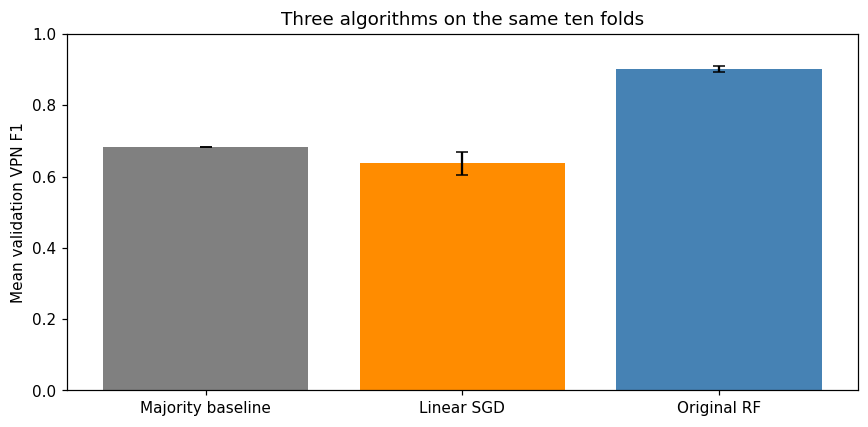

In [8]:
initial_comparison=reference_table.iloc[:3].copy()
display(initial_comparison[["Model","Training accuracy","CV training F1","CV F1 mean","CV F1 std","CV accuracy","CV VPN precision","CV VPN recall"]].round(4))
fig,ax=plt.subplots(figsize=(8,4),num="initial_algorithm_comparison")
ax.bar(["Majority baseline","Linear SGD","Original RF"],initial_comparison["CV F1 mean"],yerr=initial_comparison["CV F1 std"],capsize=4,color=["gray","darkorange","steelblue"])
ax.set(ylim=(0,1),ylabel="Mean validation VPN F1",title="Three algorithms on the same ten folds")
plt.tight_layout();plt.show()

## Part 5 — Overfitting analysis
We measure the gap by subtracting validation VPN F1 from training VPN F1 for each fitted fold model, then averaging. Both values use the same metric. Full-training accuracy is separately calculated after fitting all training rows. Training accuracy above 93% alone is not proof of overfitting.

The original forest's near-perfect training score and lower validation score motivate this experiment. The reference forests restrict depth, leaf size, split size and bootstrap sampling. RF-206 uses five candidate features per split, compared with three under Original RF's `sqrt` setting. Its higher feature count, entropy criterion and larger tree count cannot simply be described as stronger regularization.

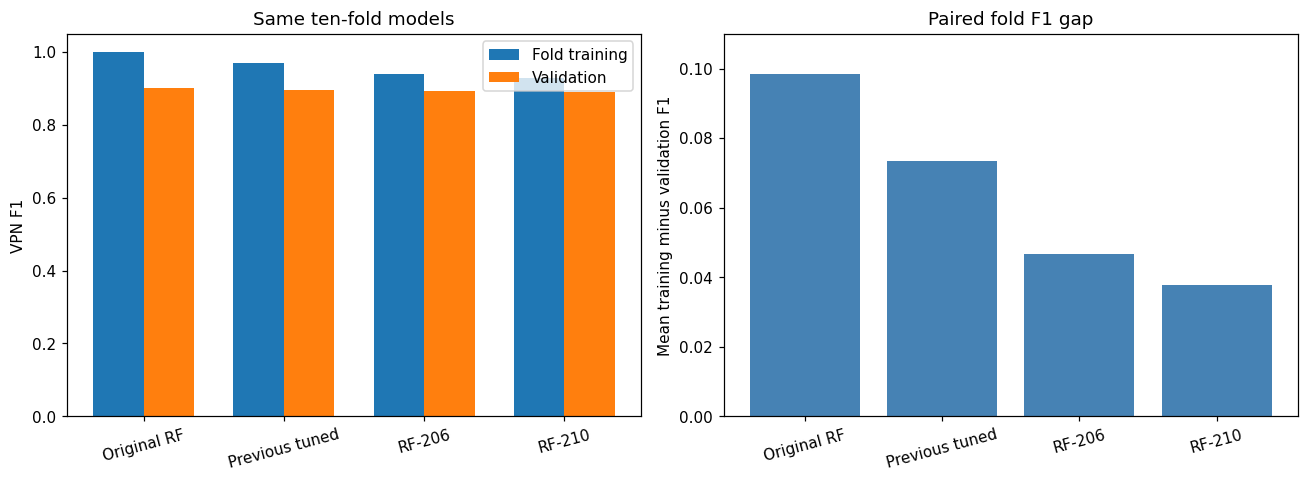

In [9]:
reference_rf=reference_table.loc[reference_table.Model.isin(RF_NAMES)].set_index("Model").loc[RF_NAMES]
fig,axes=plt.subplots(1,2,figsize=(12,4.5),num="reference_overfitting")
labels=["Original RF","Previous tuned","RF-206","RF-210"];x=np.arange(4)
axes[0].bar(x-.18,reference_rf["CV training F1"],.36,label="Fold training")
axes[0].bar(x+.18,reference_rf["CV F1 mean"],.36,label="Validation")
axes[0].set(xticks=x,xticklabels=labels,ylim=(0,1.05),ylabel="VPN F1",title="Same ten-fold models");axes[0].legend()
axes[1].bar(labels,reference_rf["CV F1 gap"],color="steelblue")
axes[1].set(ylabel="Mean training minus validation F1",title="Paired fold F1 gap",ylim=(0,.11))
for ax in axes:ax.tick_params(axis="x",rotation=15)
plt.tight_layout();plt.show()

## Part 6 — Random Forest tuning
Keep 200 trees, entropy and seed 42. Change only one setting at a time around depth 14, leaf 4, split 10, five features and a 0.70 bootstrap fraction. This gives 23 settings including the center, not a large random search. Twenty are new compared with the retained historical grids; the center and split minima 20 and 30 were already screened. They are rerun here for a complete, self-contained comparison.

The three-fold scores screen candidates efficiently. Each one-parameter change isolates an observed local effect conditional on the other center settings; it does not establish a universal causal effect. RF-206 samples more features per split than Original RF (five versus three), so reduced feature sampling cannot explain their overall difference.

In [10]:
OAT_VALUES = {"max_depth":[10,12,14,16,18], "min_samples_leaf":[2,3,4,5,6,8],
    "min_samples_split":[8,10,12,16,20,30], "max_features":[3,4,5,6,7], "max_samples":[0.5,0.6,0.7,0.8,0.9]}
oat_models = {"RF-206": clone(rf206_model)}
oat_metadata = {"RF-206":{"Varied parameter":"center","Parameter value":None,"Historical matching ID":"RF-206","New configuration":False}}
local_number = 0
for parameter, values in OAT_VALUES.items():
    center_value = rf206_model.named_steps["model"].get_params()[parameter]
    for value in values:
        if value == center_value:
            continue
        local_number += 1
        name = "Local-" + str(local_number).zfill(2)
        oat_models[name] = clone(rf206_model).set_params(**{"model__"+parameter:value})
        old_id = "RF-112" if parameter=="min_samples_split" and value==20 else (
                 "RF-211" if parameter=="min_samples_split" and value==30 else None)
        oat_metadata[name] = {"Varied parameter":parameter,"Parameter value":value,
                              "Historical matching ID":old_id,"New configuration":old_id is None}
assert len(oat_models) == 23 and sum(v["New configuration"] for v in oat_metadata.values()) == 20
screen_rows, screen_folds = [], []
for name, pipeline in oat_models.items():
    print("Three-fold local screening:",name,oat_metadata[name],flush=True)
    row, folds, _ = evaluate_model(name,pipeline,X_train,y_train,cv3,"OAT screening",full_fit=False)
    row.update(oat_metadata[name]); screen_rows.append(row); screen_folds.append(folds)
    save_checkpoint("oat_screening",screen_rows,screen_folds)
screening_table = pd.DataFrame(screen_rows)
screening_fold_scores = pd.concat(screen_folds,ignore_index=True)
display(screening_table[["Model","Varied parameter","Parameter value","CV training accuracy",
    "CV training F1","CV F1 mean","CV F1 std","CV F1 gap"]].round(4))
print("Screened configurations:",len(screening_table),"; genuinely new configurations:",int(screening_table["New configuration"].sum()))

Three-fold local screening: RF-206 {'Varied parameter': 'center', 'Parameter value': None, 'Historical matching ID': 'RF-206', 'New configuration': False}
Checkpoint saved: oat_screening 1 models
Three-fold local screening: Local-01 {'Varied parameter': 'max_depth', 'Parameter value': 10, 'Historical matching ID': None, 'New configuration': True}
Checkpoint saved: oat_screening 2 models
Three-fold local screening: Local-02 {'Varied parameter': 'max_depth', 'Parameter value': 12, 'Historical matching ID': None, 'New configuration': True}
Checkpoint saved: oat_screening 3 models
Three-fold local screening: Local-03 {'Varied parameter': 'max_depth', 'Parameter value': 16, 'Historical matching ID': None, 'New configuration': True}
Checkpoint saved: oat_screening 4 models
Three-fold local screening: Local-04 {'Varied parameter': 'max_depth', 'Parameter value': 18, 'Historical matching ID': None, 'New configuration': True}
Checkpoint saved: oat_screening 5 models
Three-fold local screening: 

,Model,Varied parameter,Parameter value,CV training accuracy,CV training F1,CV F1 mean,CV F1 std,CV F1 gap
0,RF-206,center,NaN,0.9379,0.9409,0.8864,0.0009,0.0545
1,Local-01,max_depth,10.0,0.9033,0.9092,0.8729,0.0030,0.0363
2,Local-02,max_depth,12.0,0.9250,0.9290,0.8811,0.0024,0.0479
3,Local-03,max_depth,16.0,0.9453,0.9478,0.8879,0.0007,0.0599
4,Local-04,max_depth,18.0,0.9494,0.9516,0.8879,0.0003,0.0637
5,Local-05,min_samples_leaf,2.0,0.9442,0.9469,0.8872,0.0010,0.0598
6,Local-06,min_samples_leaf,3.0,0.9413,0.9442,0.8869,0.0015,0.0573
7,Local-07,min_samples_leaf,5.0,0.9342,0.9374,0.8851,0.0019,0.0523
8,Local-08,min_samples_leaf,6.0,0.9279,0.9315,0.8837,0.0019,0.0478
9,Local-09,min_samples_leaf,8.0,0.9181,0.9222,0.8818,0.0015,0.0404


Screened configurations: 23 ; genuinely new configurations: 20


## Part 7 — Advanced cross-validation
Retain four local nonreference candidates with the highest screening F1 and four near-best candidates with smaller gaps, then fill overlaps by validation F1 until eight distinct local candidates are included. Some configurations were screened in the historical experiment; their history stays labelled. Near-best screening uses the explicitly exploratory 0.010 allowance and a descriptive SD cap of 0.015. The cap is a practical stability guard, not a significance test.

The eight candidates join the four forest references and the two original algorithms, giving 14 models. All use the identical ten folds. The reference results already computed above are reused, not refitted. Full-training scores are recorded separately. Every fold's precision, recall, structural tree measurements and impurity-based feature importance is retained.

In [11]:
new_screen = screening_table.loc[screening_table["Model"] != "RF-206"].copy()
ranked_screen = new_screen.sort_values(["CV F1 mean","CV F1 std","Model"],ascending=[False,True,True],kind="stable")
screen_peak = float(screening_table["CV F1 mean"].max())
near_screen = new_screen.loc[(new_screen["CV F1 mean"] >= screen_peak-EXPLORATORY_MARGIN)
                            & (new_screen["CV F1 std"] <= STABILITY_SD_CAP)]
near_screen = near_screen.sort_values(["Selection gap","CV F1 std","CV mean nodes per tree","Model"],kind="stable")
shortlisted_ids = pd.concat([ranked_screen.head(4),near_screen.head(4),ranked_screen]).drop_duplicates("Model").head(8)["Model"].tolist()
finalist_rows = [dict(row) for row in reference_rows]
finalist_folds = [reference_fold_scores]
candidate_models = {**reference_models, **oat_models}
for name in shortlisted_ids:
    print("New finalist ten-fold evaluation:",name,flush=True)
    row, folds, fitted = evaluate_model(name,oat_models[name],X_train,y_train,cv10,"new finalist")
    row.update(oat_metadata[name]); finalist_rows.append(row); finalist_folds.append(folds); fitted_models[name]=fitted
    save_checkpoint("finalist_comparison",finalist_rows,finalist_folds)
finalists_table = pd.DataFrame(finalist_rows)
finalist_fold_scores = pd.concat(finalist_folds,ignore_index=True)
assert len(shortlisted_ids)==8 and len(finalists_table)==14
fold_hash_counts = finalist_fold_scores.groupby("Fold")[["Training row hash","Validation row hash"]].nunique()
assert (fold_hash_counts==1).all().all(), "Finalist folds differ"
display(finalists_table[["Model","Training accuracy","Training VPN F1","CV training F1","CV F1 mean",
    "CV F1 std","CV F1 gap","CV accuracy","CV VPN precision","CV VPN recall","CV folds"]].round(4))

New finalist ten-fold evaluation: Local-21
Checkpoint saved: finalist_comparison 7 models
New finalist ten-fold evaluation: Local-03
Checkpoint saved: finalist_comparison 8 models
New finalist ten-fold evaluation: Local-04
Checkpoint saved: finalist_comparison 9 models
New finalist ten-fold evaluation: Local-22
Checkpoint saved: finalist_comparison 10 models
New finalist ten-fold evaluation: Local-14
Checkpoint saved: finalist_comparison 11 models
New finalist ten-fold evaluation: Local-09
Checkpoint saved: finalist_comparison 12 models
New finalist ten-fold evaluation: Local-13
Checkpoint saved: finalist_comparison 13 models
New finalist ten-fold evaluation: Local-19
Checkpoint saved: finalist_comparison 14 models


,Model,Training accuracy,Training VPN F1,CV training F1,CV F1 mean,CV F1 std,CV F1 gap,CV accuracy,CV VPN precision,CV VPN recall,CV folds
0,DummyClassifier,0.5184,0.6828,0.6828,0.6828,0.0003,0.0000,0.5184,0.5184,1.0000,10
1,SGDClassifier,0.5893,0.6420,0.6361,0.6369,0.0326,-0.0008,0.5922,0.5907,0.6939,10
2,Original Random Forest,0.9999,0.9999,1.0000,0.9016,0.0072,0.0984,0.8972,0.8947,0.9088,10
3,Previous Tuned Random Forest,0.9673,0.9688,0.9699,0.8965,0.0090,0.0733,0.8908,0.8812,0.9126,10
4,RF-206,0.9376,0.9406,0.9405,0.8938,0.0087,0.0467,0.8878,0.8772,0.9112,10
5,RF-210,0.9257,0.9292,0.9282,0.8904,0.0075,0.0378,0.8842,0.8736,0.9081,10
6,Local-21,0.9405,0.9433,0.9440,0.8932,0.0088,0.0508,0.8872,0.8774,0.9097,10
7,Local-03,0.9445,0.9471,0.9475,0.8939,0.0083,0.0536,0.8880,0.8785,0.9099,10
8,Local-04,0.9493,0.9515,0.9521,0.8959,0.0076,0.0562,0.8903,0.8817,0.9107,10
9,Local-22,0.9441,0.9468,0.9470,0.8948,0.0081,0.0523,0.8888,0.8787,0.9116,10


## Part 8 — Final model-selection analysis
Criterion A maximizes mean validation F1. Criterion B applies the unchanged historical 0.005 allowance and its original tie-breakers. Criterion C is **post-hoc exploratory**: allow 0.010 below the best observed F1, require fold SD no greater than 0.015, then prefer the smallest gap among Pareto-efficient eligible models. Further C ties prefer lower SD, fewer mean nodes per tree and a fixed parameter order. If no model passes the stability guard, report that and fall back to A without silently relaxing the guard.

The global Pareto frontier uses the specified two-score definition: a model is dominated if another has at least its validation F1 and no larger paired gap, with at least one strict improvement. Tree complexity is reported alongside the frontier rather than silently changing that definition. The eligible/stable Pareto pool for C is also recorded.

We report paired fold differences, their descriptive variation, ranges and win counts. Folds share training observations, so they are not ten independent datasets; no significance test or independent confidence interval is claimed. A smaller gap with lower validation F1 is a trade-off, not proof of higher predictive performance. The recommendation uses C as the disclosed practical preference, while A and B remain visible. It is frozen before subsequent diagnostic checks.

### Observed sensitivity in the saved run
Criterion A and the unchanged historical criterion B select Original RF, with mean ten-fold F1 0.901607. The exploratory criterion C selects RF-206, with F1 0.893824 and paired gap 0.046692. Its F1 is 0.007783 below Original, while its gap is 52.5% smaller. This is a disclosed preference for a trade-off, not a newly demonstrated gain in predictive accuracy.

The strongest genuinely new finalist is Local-04, which increases depth from 14 to 18. Its F1 rises to 0.895882, but its gap rises to 0.056215. It does not dominate RF-206. RF-206 beats Original in only one of the ten matched folds. Their paired F1 difference has mean −0.007783 and descriptive SD 0.005937, so the loss should not be dismissed because separate-model SDs overlap.


In [12]:
def parameter_complexity(params):
    depth=params["max_depth"]; sampled_features=params["max_features"]
    if sampled_features=="sqrt": sampled_features=int(np.sqrt(len(FEATURES)))
    elif isinstance(sampled_features,float): sampled_features=max(1,int(sampled_features*len(FEATURES)))
    return (1000000 if depth is None else depth,-params["min_samples_leaf"],-params["min_samples_split"],
            sampled_features,1.0 if params["max_samples"] is None else params["max_samples"],
            params["n_estimators"],params["criterion"]!="gini")

def pareto_mask(frame):
    flags=[]
    for _,row in frame.iterrows():
        dominates=(frame["CV F1 mean"]>=row["CV F1 mean"]) & (frame["CV F1 gap"]<=row["CV F1 gap"]) & (
            (frame["CV F1 mean"]>row["CV F1 mean"]) | (frame["CV F1 gap"]<row["CV F1 gap"]))
        flags.append(not bool(dominates.any()))
    return pd.Series(flags,index=frame.index,dtype=bool)

def choose_criteria(forest_table):
    frame=forest_table.copy()
    frame["Complexity order"]=[parameter_complexity(p) for p in frame["params"]]
    highest=frame.sort_values(["CV F1 mean","CV F1 std","Complexity order","Model"],ascending=[False,True,True,True],kind="stable").iloc[0]
    peak=float(highest["CV F1 mean"])
    b_pool=frame.loc[frame["CV F1 mean"]>=peak-HISTORICAL_MARGIN]
    historical=b_pool.sort_values(["Selection gap","CV training accuracy","CV F1 std","Complexity order","Model"],kind="stable").iloc[0]
    c_pool=frame.loc[(frame["CV F1 mean"]>=peak-EXPLORATORY_MARGIN)&(frame["CV F1 std"]<=STABILITY_SD_CAP)].copy()
    if len(c_pool):
        c_frontier=c_pool.loc[pareto_mask(c_pool)]
        exploratory=c_frontier.sort_values(["Selection gap","CV F1 std","CV mean nodes per tree","Complexity order","Model"],kind="stable").iloc[0]
        c_status="Eligible stable Pareto compromise"
    else:
        exploratory=highest; c_status="No stable eligible model; disclosed fallback to A"
    return highest,historical,exploratory,c_status,c_pool

forest_finalists=finalists_table.loc[finalists_table["Algorithm"]=="RandomForestClassifier"].copy()
best_a,best_b,best_c,c_status,c_pool=choose_criteria(forest_finalists)
criterion_results=pd.DataFrame([{"Criterion":label,"Model":row["Model"],"Mean CV F1":row["CV F1 mean"],
    "CV F1 SD":row["CV F1 std"],"Paired F1 gap":row["CV F1 gap"],"Explanation":explanation}
    for label,row,explanation in [("A",best_a,"Highest observed ten-fold F1"),
        ("B",best_b,"Historical 0.005 rule, unchanged"),("C",best_c,"Post-hoc exploratory 0.010 rule: "+c_status)]])
pareto_table=forest_finalists.copy();pareto_table["Pareto efficient"]=pareto_mask(pareto_table)
pareto_table["C eligible and stable"]=pareto_table["Model"].isin(c_pool["Model"])
paired_rows=[]; paired_summaries=[]
for reference_name in ["Original Random Forest","RF-206"]:
    reference_values=np.asarray(forest_finalists.loc[forest_finalists.Model==reference_name,"Validation fold F1"].iloc[0])
    for _,row in forest_finalists.iterrows():
        if row["Model"]==reference_name: continue
        difference=np.asarray(row["Validation fold F1"])-reference_values
        paired_summaries.append({"Model":row["Model"],"Reference":reference_name,"Mean paired F1 difference":float(difference.mean()),
            "Paired difference SD":float(difference.std()),"Minimum":float(difference.min()),"Maximum":float(difference.max()),
            "25th percentile":float(np.quantile(difference,.25)),"75th percentile":float(np.quantile(difference,.75)),
            "Folds higher":int((difference>0).sum()),"Folds equal":int((difference==0).sum()),"Folds lower":int((difference<0).sum())})
        paired_rows.extend({"Model":row["Model"],"Reference":reference_name,"Fold":i+1,"F1 difference":float(value)} for i,value in enumerate(difference))
paired_summary=pd.DataFrame(paired_summaries);paired_differences=pd.DataFrame(paired_rows)
recommended_id=str(best_c["Model"])
highest_validation_id=str(best_a["Model"]);historical_rule_id=str(best_b["Model"])
genuinely_new_finalist_ids=[name for name in shortlisted_ids if oat_metadata[name]["New configuration"]]
assert genuinely_new_finalist_ids, "No genuinely new finalist available for the requested learning curve"
strongest_new_id=str(forest_finalists.loc[forest_finalists.Model.isin(genuinely_new_finalist_ids)].sort_values(["CV F1 mean","CV F1 std","Model"],ascending=[False,True,True],kind="stable").iloc[0]["Model"])
final_model=fitted_models[recommended_id]
selected_rf_params=final_model.named_steps["model"].get_params()
selected_params={"model__"+key:value for key,value in selected_rf_params.items()}
required_comparison=finalists_table.loc[finalists_table.Model.isin(reference_models)].copy()
recommended_row=dict(best_c);recommended_row["Model"]="Final Recommended Random Forest"
required_comparison=pd.concat([required_comparison,pd.DataFrame([recommended_row])],ignore_index=True)
models={"Original Random Forest":fitted_models["Original Random Forest"],"RF-206":fitted_models["RF-206"],
        "Strongest new refinement":fitted_models[strongest_new_id],"Final Recommended Random Forest":final_model}
final_selection={"frozen_utc":datetime.now(timezone.utc).isoformat(),"recommendation":recommended_id,
    "criterion":"C: explicitly post-hoc exploratory practical compromise","status":c_status,
    "historical_margin":HISTORICAL_MARGIN,"exploratory_margin":EXPLORATORY_MARGIN,"stability_sd_cap":STABILITY_SD_CAP,
    "highest_validation_id":highest_validation_id,"historical_rule_id":historical_rule_id,
    "strongest_new_id":strongest_new_id,"screened_configurations":len(screening_table),
    "genuinely_new_configurations":int(screening_table["New configuration"].sum()),
    "local_nonreference_finalists":len(shortlisted_ids),"genuinely_new_finalists":len(genuinely_new_finalist_ids),
    "all_finalists":len(finalists_table),"rf_finalists":len(forest_finalists),
    "params":selected_rf_params,"training_accuracy":float(best_c["Training accuracy"]),"training_f1":float(best_c["Training VPN F1"]),
    "cv_f1":float(best_c["CV F1 mean"]),"cv_f1_std":float(best_c["CV F1 std"]),"paired_f1_gap":float(best_c["CV F1 gap"]),
    "cv_accuracy":float(best_c["CV accuracy"]),"cv_precision":float(best_c["CV VPN precision"]),"cv_recall":float(best_c["CV VPN recall"]),
    "new_development_test_evaluation":False,"nested_check_can_change_recommendation":False}
display(criterion_results.round(5));display(paired_summary.round(5))
print("FROZEN RECOMMENDATION",json.dumps(final_selection,indent=2))
(OUT/"final_selection.json").write_text(json.dumps(final_selection,indent=2))
criterion_results.to_csv(OUT/"selection_criteria.csv",index=False)
pareto_table.to_csv(OUT/"pareto_candidates.csv",index=False)
paired_summary.to_csv(OUT/"paired_difference_summary.csv",index=False)
paired_differences.to_csv(OUT/"paired_fold_differences.csv",index=False)

,Criterion,Model,Mean CV F1,CV F1 SD,Paired F1 gap,Explanation
0,A,Original Random Forest,0.90161,0.00719,0.09839,Highest observed ten-fold F1
1,B,Original Random Forest,0.90161,0.00719,0.09839,"Historical 0.005 rule, unchanged"
2,C,RF-206,0.89382,0.00869,0.04669,Post-hoc exploratory 0.010 rule: Eligible stable Pareto compromise


,Model,Reference,Mean paired F1 difference,Paired difference SD,Minimum,Maximum,25th percentile,75th percentile,Folds higher,Folds equal,Folds lower
0,Previous Tuned Random Forest,Original Random Forest,-0.00506,0.00458,-0.01130,0.00317,-0.00975,-0.00181,1,0,9
1,RF-206,Original Random Forest,-0.00778,0.00594,-0.01963,0.00327,-0.00975,-0.00471,1,0,9
2,RF-210,Original Random Forest,-0.01116,0.00574,-0.02193,0.00060,-0.01372,-0.00825,1,0,9
3,Local-21,Original Random Forest,-0.00842,0.00575,-0.02069,-0.00055,-0.01080,-0.00424,0,0,10
4,Local-03,Original Random Forest,-0.00775,0.00511,-0.01510,0.00075,-0.01087,-0.00330,1,0,9
5,Local-04,Original Random Forest,-0.00573,0.00478,-0.01381,0.00327,-0.00898,-0.00287,1,0,9
6,Local-22,Original Random Forest,-0.00686,0.00700,-0.01816,0.00562,-0.01267,-0.00238,2,0,8
7,Local-14,Original Random Forest,-0.01548,0.00687,-0.02692,-0.00370,-0.02014,-0.01217,0,0,10
8,Local-09,Original Random Forest,-0.01281,0.00588,-0.02233,0.00060,-0.01698,-0.01081,1,0,9
9,Local-13,Original Random Forest,-0.01210,0.00660,-0.02151,0.00134,-0.01745,-0.01028,1,0,9


FROZEN RECOMMENDATION {
  "frozen_utc": "2026-10-20T10:42:21.044879+00:00",
  "recommendation": "RF-206",
  "criterion": "C: explicitly post-hoc exploratory practical compromise",
  "status": "Eligible stable Pareto compromise",
  "historical_margin": 0.005,
  "exploratory_margin": 0.01,
  "stability_sd_cap": 0.015,
  "highest_validation_id": "Original Random Forest",
  "historical_rule_id": "Original Random Forest",
  "strongest_new_id": "Local-04",
  "screened_configurations": 23,
  "genuinely_new_configurations": 20,
  "local_nonreference_finalists": 8,
  "genuinely_new_finalists": 6,
  "all_finalists": 14,
  "rf_finalists": 12,
  "params": {
    "bootstrap": true,
    "ccp_alpha": 0.0,
    "class_weight": null,
    "criterion": "entropy",
    "max_depth": 14,
    "max_features": 5,
    "max_leaf_nodes": null,
    "max_samples": 0.7,
    "min_impurity_decrease": 0.0,
    "min_samples_leaf": 4,
    "min_samples_split": 10,
    "min_weight_fraction_leaf": 0.0,
    "monotonic_cst": nul

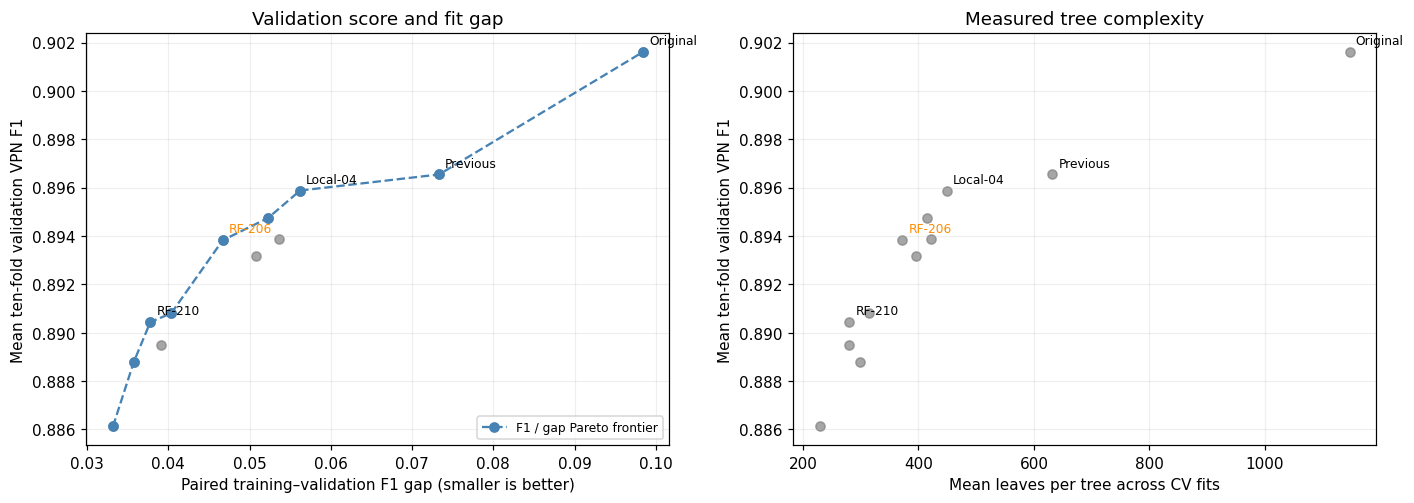

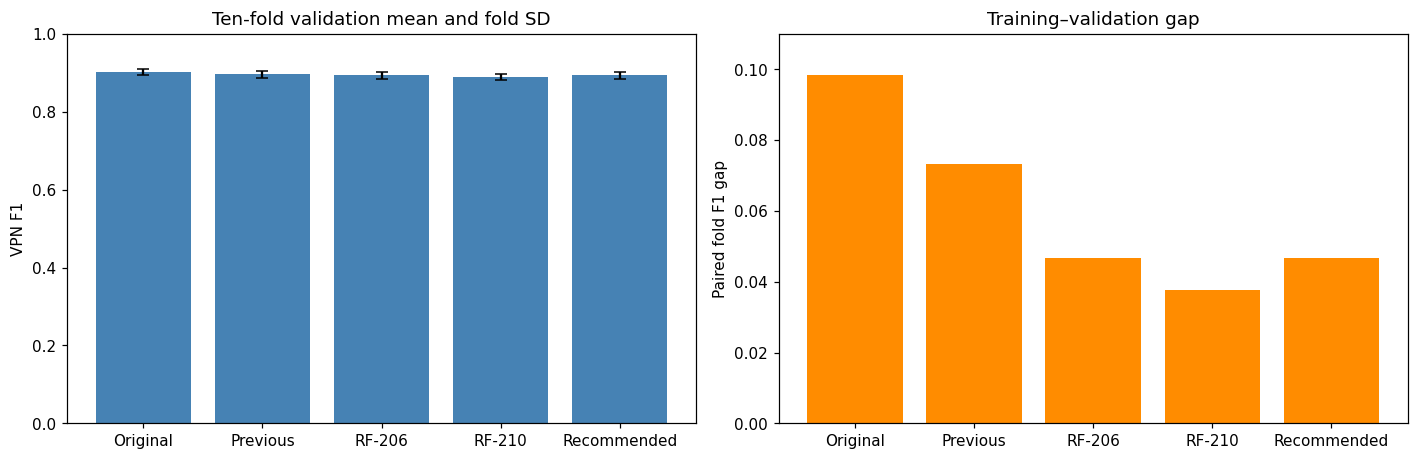

In [13]:
fig,axes=plt.subplots(1,2,figsize=(13,4.7),num="pareto_and_complexity")
front=pareto_table.loc[pareto_table["Pareto efficient"]].sort_values("CV F1 gap")
axes[0].scatter(pareto_table["CV F1 gap"],pareto_table["CV F1 mean"],color="gray",alpha=.7)
axes[0].plot(front["CV F1 gap"],front["CV F1 mean"],"o--",color="steelblue",label="F1 / gap Pareto frontier")
axes[1].scatter(pareto_table["CV mean leaves per tree"],pareto_table["CV F1 mean"],color="gray",alpha=.7)
labels_to_show=list(dict.fromkeys(RF_NAMES+[recommended_id,strongest_new_id]))
for name in labels_to_show:
    row=pareto_table.loc[pareto_table.Model==name].iloc[0]
    label={"Original Random Forest":"Original","Previous Tuned Random Forest":"Previous"}.get(name,name)
    color="darkorange" if name==recommended_id else "black"
    axes[0].annotate(label,(row["CV F1 gap"],row["CV F1 mean"]),xytext=(4,5),textcoords="offset points",fontsize=8,color=color)
    axes[1].annotate(label,(row["CV mean leaves per tree"],row["CV F1 mean"]),xytext=(4,5),textcoords="offset points",fontsize=8,color=color)
axes[0].set(xlabel="Paired training–validation F1 gap (smaller is better)",ylabel="Mean ten-fold validation VPN F1",title="Validation score and fit gap")
axes[0].legend(loc="lower right",fontsize=8)
axes[1].set(xlabel="Mean leaves per tree across CV fits",ylabel="Mean ten-fold validation VPN F1",title="Measured tree complexity")
for ax in axes:ax.grid(alpha=.2)
plt.tight_layout();plt.show()
comparison_plot=required_comparison.iloc[2:].copy()
fig,axes=plt.subplots(1,2,figsize=(13,4.3),num="final_model_comparison")
short_labels=["Original","Previous","RF-206","RF-210","Recommended"]
axes[0].bar(short_labels,comparison_plot["CV F1 mean"],yerr=comparison_plot["CV F1 std"],capsize=4,color="steelblue")
axes[0].set(ylim=(0,1),ylabel="VPN F1",title="Ten-fold validation mean and fold SD")
axes[1].bar(short_labels,comparison_plot["CV F1 gap"],color="darkorange")
axes[1].set(ylabel="Paired fold F1 gap",title="Training–validation gap",ylim=(0,.11))
plt.tight_layout();plt.show()

### Conditional nested check of the local selection procedure
This additional check uses three outer folds. Within each outer training subset, evaluate the fixed 23-setting OAT family plus Original RF, Previous Tuned RF and RF-210 with three inner folds, then apply exploratory criterion C. The global ten-fold shortlist is not reused. Fit the chosen model only on that outer training subset and evaluate its excluded outer fold. No outer validation label participates in selection.

This requires 234 inner CV fits plus three selected-model refits. It evaluates this **three-fold local selection procedure**, not the complete historical search or the three-to-ten-fold finalist workflow. RF-206 and the local search family were chosen after earlier analysis of the same overall data, and cleaning was fixed using the original full dataset. Nested splitting cannot erase that history. These three outer scores are a conditional diagnostic, not a genuinely independent estimate, significance test or new test dataset. They cannot change the frozen recommendation.

In [14]:
nested_models={**oat_models, **{name:reference_models[name] for name in ["Original Random Forest","Previous Tuned Random Forest","RF-210"]}}
assert len(nested_models)==26
outer_cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED)
nested_rows=[];nested_inner_rows=[];nested_fold_frames=[]
for outer_fold,(outer_train_index,outer_valid_index) in enumerate(outer_cv.split(X_train,y_train),1):
    X_outer_train=X_train.iloc[outer_train_index];y_outer_train=y_train.iloc[outer_train_index]
    X_outer_valid=X_train.iloc[outer_valid_index];y_outer_valid=y_train.iloc[outer_valid_index]
    inner_rows=[]
    for name,pipeline in nested_models.items():
        print("Conditional nested check, outer fold",outer_fold,"candidate",name,flush=True)
        row,folds,_=evaluate_model(name,pipeline,X_outer_train,y_outer_train,cv3,
                                   "nested outer "+str(outer_fold),full_fit=False)
        row["Outer fold"]=outer_fold;inner_rows.append(row);nested_inner_rows.append(row)
        folds["Outer fold"]=outer_fold;nested_fold_frames.append(folds)
        save_checkpoint("nested_inner_results",nested_inner_rows,nested_fold_frames)
    inner_table=pd.DataFrame(inner_rows)
    _,_,chosen,status,_=choose_criteria(inner_table)
    chosen_name=str(chosen["Model"])
    outer_model=clone(nested_models[chosen_name]).fit(X_outer_train,y_outer_train)
    outer_training_prediction=outer_model.predict(X_outer_train)
    outer_validation_prediction=outer_model.predict(X_outer_valid)
    nested_rows.append({"Outer fold":outer_fold,"Selected model":chosen_name,"Selection status":status,
        "Selected parameters":outer_model.named_steps["model"].get_params(),
        "Inner mean validation F1":float(chosen["CV F1 mean"]),"Inner F1 SD":float(chosen["CV F1 std"]),
        "Inner paired F1 gap":float(chosen["CV F1 gap"]),"Outer training rows":len(outer_train_index),
        "Outer validation rows":len(outer_valid_index),"Outer training row hash":row_hash(X_outer_train),
        "Outer validation row hash":row_hash(X_outer_valid),
        "Outer training F1":float(f1_score(y_outer_train,outer_training_prediction)),
        "Outer validation F1":float(f1_score(y_outer_valid,outer_validation_prediction)),
        "Outer validation accuracy":float(accuracy_score(y_outer_valid,outer_validation_prediction)),
        "Outer validation precision":float(precision_score(y_outer_valid,outer_validation_prediction,zero_division=0)),
        "Outer validation recall":float(recall_score(y_outer_valid,outer_validation_prediction,zero_division=0))})
    pd.DataFrame(nested_rows).to_csv(OUT/"nested_outer_results.csv",index=False)
nested_table=pd.DataFrame(nested_rows)
nested_inner_table=pd.DataFrame(nested_inner_rows)
nested_fold_scores=pd.concat(nested_fold_frames,ignore_index=True)
nested_summary={"outer_folds":3,"inner_folds":3,"candidate_settings":26,"inner_cv_fits":234,
    "mean_outer_f1":float(nested_table["Outer validation F1"].mean()),
    "outer_f1_sd":float(nested_table["Outer validation F1"].std(ddof=0)),
    "outer_scores":nested_table["Outer validation F1"].tolist(),
    "selected_models":nested_table["Selected model"].tolist(),
    "limitation":"Conditional on previously chosen RF-206 center and preprocessing; checks the local three-fold procedure, not an independent or unbiased full-project estimate."}
display(nested_table.drop(columns=["Selected parameters","Outer training row hash","Outer validation row hash"]).round(4))
print(json.dumps(nested_summary,indent=2))
print("Frozen recommendation unchanged:",recommended_id)

Conditional nested check, outer fold 1 candidate RF-206
Checkpoint saved: nested_inner_results 1 models
Conditional nested check, outer fold 1 candidate Local-01
Checkpoint saved: nested_inner_results 2 models
Conditional nested check, outer fold 1 candidate Local-02
Checkpoint saved: nested_inner_results 3 models
Conditional nested check, outer fold 1 candidate Local-03
Checkpoint saved: nested_inner_results 4 models
Conditional nested check, outer fold 1 candidate Local-04
Checkpoint saved: nested_inner_results 5 models
Conditional nested check, outer fold 1 candidate Local-05
Checkpoint saved: nested_inner_results 6 models
Conditional nested check, outer fold 1 candidate Local-06
Checkpoint saved: nested_inner_results 7 models
Conditional nested check, outer fold 1 candidate Local-07
Checkpoint saved: nested_inner_results 8 models
Conditional nested check, outer fold 1 candidate Local-08
Checkpoint saved: nested_inner_results 9 models
Conditional nested check, outer fold 1 candidate

,Outer fold,Selected model,Selection status,Inner mean validation F1,Inner F1 SD,Inner paired F1 gap,Outer training rows,Outer validation rows,Outer training F1,Outer validation F1,Outer validation accuracy,Outer validation precision,Outer validation recall
0,1,Local-20,Eligible stable Pareto compromise,0.8752,0.0060,0.0599,9588,4795,0.9355,0.8845,0.8786,0.8730,0.8962
1,2,Local-12,Eligible stable Pareto compromise,0.8761,0.0051,0.0558,9589,4794,0.9316,0.8854,0.8776,0.8600,0.9123
2,3,Local-08,Eligible stable Pareto compromise,0.8739,0.0008,0.0543,9589,4794,0.9313,0.8841,0.8771,0.8652,0.9038


{
  "outer_folds": 3,
  "inner_folds": 3,
  "candidate_settings": 26,
  "inner_cv_fits": 234,
  "mean_outer_f1": 0.8846432850872024,
  "outer_f1_sd": 0.0005418547509945803,
  "outer_scores": [
    0.8844779674473998,
    0.8853739504003124,
    0.884077937413895
  ],
  "selected_models": [
    "Local-20",
    "Local-12",
    "Local-08"
  ],
  "limitation": "Conditional on previously chosen RF-206 center and preprocessing; checks the local three-fold procedure, not an independent or unbiased full-project estimate."
}
Frozen recommendation unchanged: RF-206


## Part 9 — Learning curves and validation curves
Learning curves compare Original RF, RF-206 and the strongest genuinely new finalist at five training sizes with the same three shuffled stratified folds. Shading represents one fold standard deviation, not a confidence interval. The largest fit uses two-thirds of the training partition because one fold remains excluded.

Validation curves reuse the three-fold one-parameter screening scores around RF-206. All other settings remain at the center. Reading both training and validation F1 helps distinguish a smaller gap from excessive restriction. These diagnostic curves cannot change the frozen recommendation.

### Reading the measured curves
RF-206 validation F1 rises from 0.8401 to 0.8873 as training rows per fit increase from 1,917 to 9,588, while its largest-point gap is still 0.0538. Original reaches validation F1 0.8943 with a 0.1056 gap. These are three-fold diagnostics, not the ten-fold finalist scores. The learning-curve routine shuffles row order before taking subsets, so even its largest point need not exactly match the screening score.

In the controlled depth sweep, depth 10 gives training/validation F1 0.9092/0.8729 versus 0.9409/0.8864 at depth 14. Both scores fall with the stronger restriction, indicating relative underfitting. Larger leaf and split minima also eventually lower both scores. A smaller gap by itself is not an improvement.


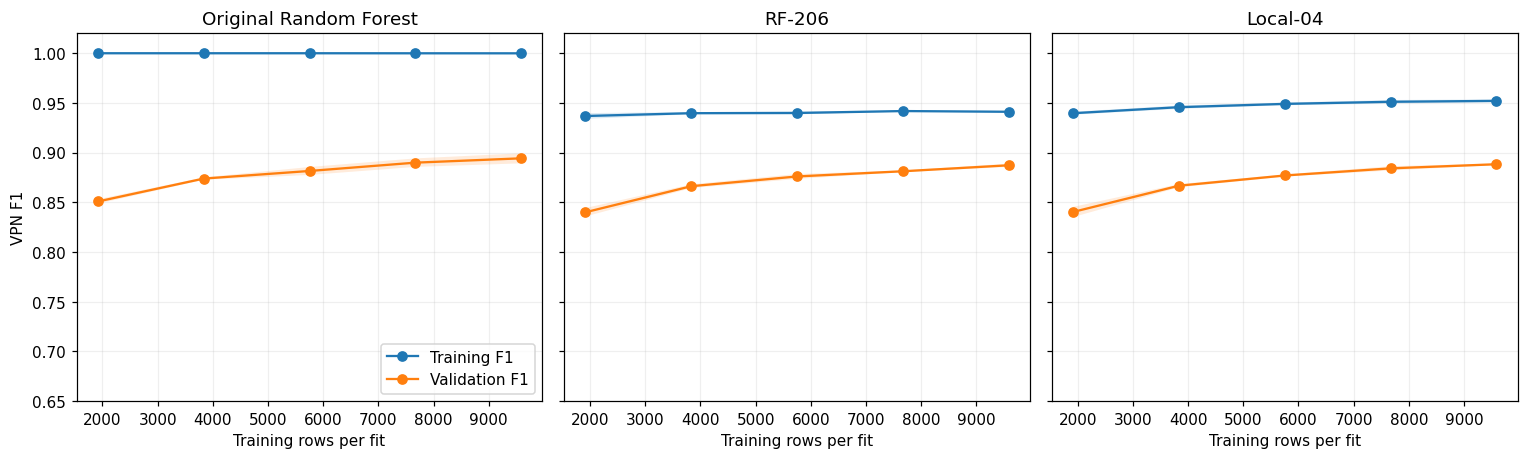

,Model,Training rows per fit,Training F1,Training F1 std,Validation F1,Validation F1 std,F1 gap
0,Original Random Forest,1917,1.0000,0.0000,0.8509,0.0022,0.1491
1,Original Random Forest,3835,1.0000,0.0000,0.8739,0.0012,0.1261
2,Original Random Forest,5752,1.0000,0.0000,0.8816,0.0040,0.1184
3,Original Random Forest,7670,1.0000,0.0001,0.8900,0.0043,0.1100
4,Original Random Forest,9588,0.9999,0.0000,0.8943,0.0051,0.1056
5,RF-206,1917,0.9369,0.0029,0.8401,0.0042,0.0968
6,RF-206,3835,0.9397,0.0011,0.8663,0.0019,0.0734
7,RF-206,5752,0.9399,0.0014,0.8761,0.0025,0.0639
8,RF-206,7670,0.9418,0.0005,0.8813,0.0008,0.0606
9,RF-206,9588,0.9411,0.0009,0.8873,0.0017,0.0538


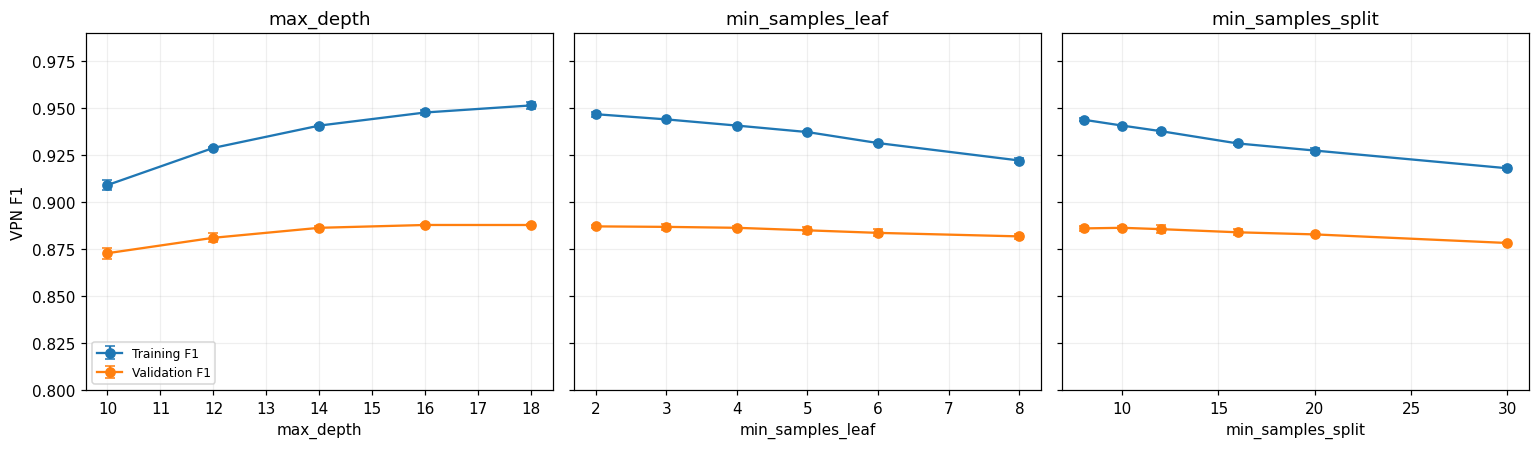

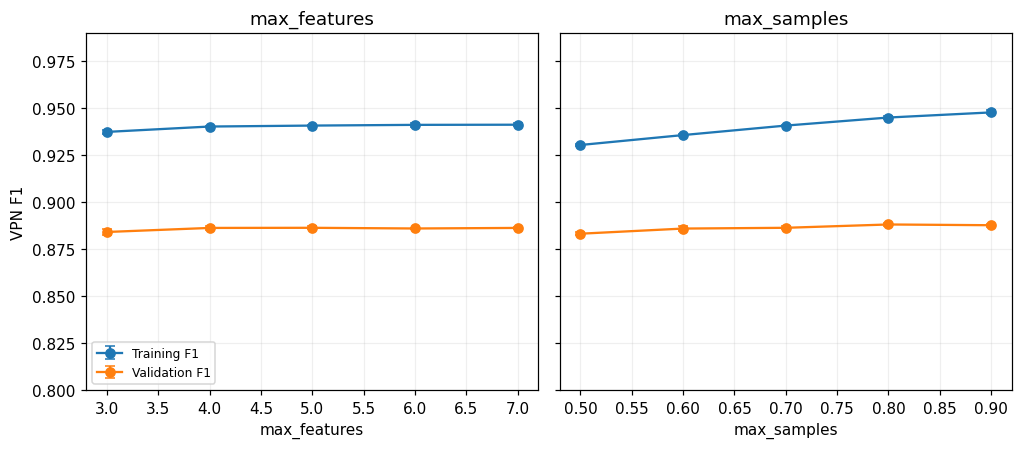

,Parameter,Value,Model,Training F1,Training F1 std,Validation F1,Validation F1 std,F1 gap
0,max_depth,10.0,Local-01,0.9092,0.0027,0.8729,0.0030,0.0363
1,max_depth,12.0,Local-02,0.9290,0.0004,0.8811,0.0024,0.0479
2,max_depth,14.0,RF-206,0.9409,0.0004,0.8864,0.0009,0.0545
3,max_depth,16.0,Local-03,0.9478,0.0014,0.8879,0.0007,0.0599
4,max_depth,18.0,Local-04,0.9516,0.0020,0.8879,0.0003,0.0637
5,min_samples_leaf,2.0,Local-05,0.9469,0.0014,0.8872,0.0010,0.0598
6,min_samples_leaf,3.0,Local-06,0.9442,0.0000,0.8869,0.0015,0.0573
7,min_samples_leaf,4.0,RF-206,0.9409,0.0004,0.8864,0.0009,0.0545
8,min_samples_leaf,5.0,Local-07,0.9374,0.0006,0.8851,0.0019,0.0523
9,min_samples_leaf,6.0,Local-08,0.9315,0.0005,0.8837,0.0019,0.0478


In [15]:
learning_rows=[]
curve_models={"Original Random Forest":candidate_models["Original Random Forest"],"RF-206":candidate_models["RF-206"],strongest_new_id:candidate_models[strongest_new_id]}
fig,axes=plt.subplots(1,3,figsize=(14,4.3),sharey=True,num="learning_curves")
for ax,(name,pipeline) in zip(axes,curve_models.items()):
    sizes,tr,va=learning_curve(clone(pipeline),X_train,y_train,cv=cv3,scoring="f1",train_sizes=np.linspace(.2,1,5),shuffle=True,random_state=SEED,n_jobs=2)
    for j,size in enumerate(sizes):
        learning_rows.append({"Model":name,"Training rows per fit":int(size),"Training F1":tr[j].mean(),"Training F1 std":tr[j].std(),"Validation F1":va[j].mean(),"Validation F1 std":va[j].std(),"F1 gap":tr[j].mean()-va[j].mean(),"Training fold F1":tr[j].tolist(),"Validation fold F1":va[j].tolist()})
    ax.plot(sizes,tr.mean(axis=1),"o-",label="Training F1");ax.plot(sizes,va.mean(axis=1),"o-",label="Validation F1")
    ax.fill_between(sizes,tr.mean(axis=1)-tr.std(axis=1),tr.mean(axis=1)+tr.std(axis=1),alpha=.15)
    ax.fill_between(sizes,va.mean(axis=1)-va.std(axis=1),va.mean(axis=1)+va.std(axis=1),alpha=.15)
    ax.set(title=name,xlabel="Training rows per fit",ylim=(.65,1.02));ax.grid(alpha=.2)
axes[0].set_ylabel("VPN F1");axes[0].legend(loc="lower right")
plt.tight_layout();plt.show()
learning_curve_table=pd.DataFrame(learning_rows)
display(learning_curve_table.drop(columns=["Training fold F1","Validation fold F1"]).round(4))
validation_rows=[]
for parameter,values in OAT_VALUES.items():
    for value in values:
        if value==rf206_model.named_steps["model"].get_params()[parameter]:
            row=screening_table.loc[screening_table.Model=="RF-206"].iloc[0]
        else:
            row=screening_table.loc[(screening_table["Varied parameter"]==parameter)&(screening_table["Parameter value"]==value)].iloc[0]
        validation_rows.append({"Parameter":parameter,"Value":value,"Model":row["Model"],"Training F1":row["CV training F1"],"Training F1 std":np.std(row["Training fold F1"]),"Validation F1":row["CV F1 mean"],"Validation F1 std":row["CV F1 std"],"F1 gap":row["CV F1 gap"]})
validation_curve_table=pd.DataFrame(validation_rows)
for figure_name,parameters in [("validation_curves",["max_depth","min_samples_leaf","min_samples_split"]),("sampling_curves",["max_features","max_samples"])]:
    fig,axes=plt.subplots(1,len(parameters),figsize=(4.7*len(parameters),4.2),sharey=True,num=figure_name)
    for ax,parameter in zip(axes,parameters):
        points=validation_curve_table.loc[validation_curve_table.Parameter==parameter].sort_values("Value")
        ax.errorbar(points.Value,points["Training F1"],yerr=points["Training F1 std"],marker="o",capsize=3,label="Training F1")
        ax.errorbar(points.Value,points["Validation F1"],yerr=points["Validation F1 std"],marker="o",capsize=3,label="Validation F1")
        ax.set(xlabel=parameter,title=parameter,ylim=(.8,.99));ax.grid(alpha=.2)
    axes[0].set_ylabel("VPN F1");axes[0].legend(loc="lower left",fontsize=8)
    plt.tight_layout();plt.show()
display(validation_curve_table.round(4))
learning_curve_table.to_csv(OUT/"learning_curves.csv",index=False)
validation_curve_table.to_csv(OUT/"validation_curves.csv",index=False)

### Feature-importance stability
We show impurity importance across the recommended model's ten CV fits, plus permutation importance on three training-partition validation folds. For each excluded fold, shuffle a feature five times and measure the decrease in VPN F1. Both methods use training-partition data only. The permutation chart shows between-fold SD of the five-repeat means.

Correlated features may substitute for one another, and importance can change between folds. These descriptive results do not prove causal relationships or justify removing features after selection.

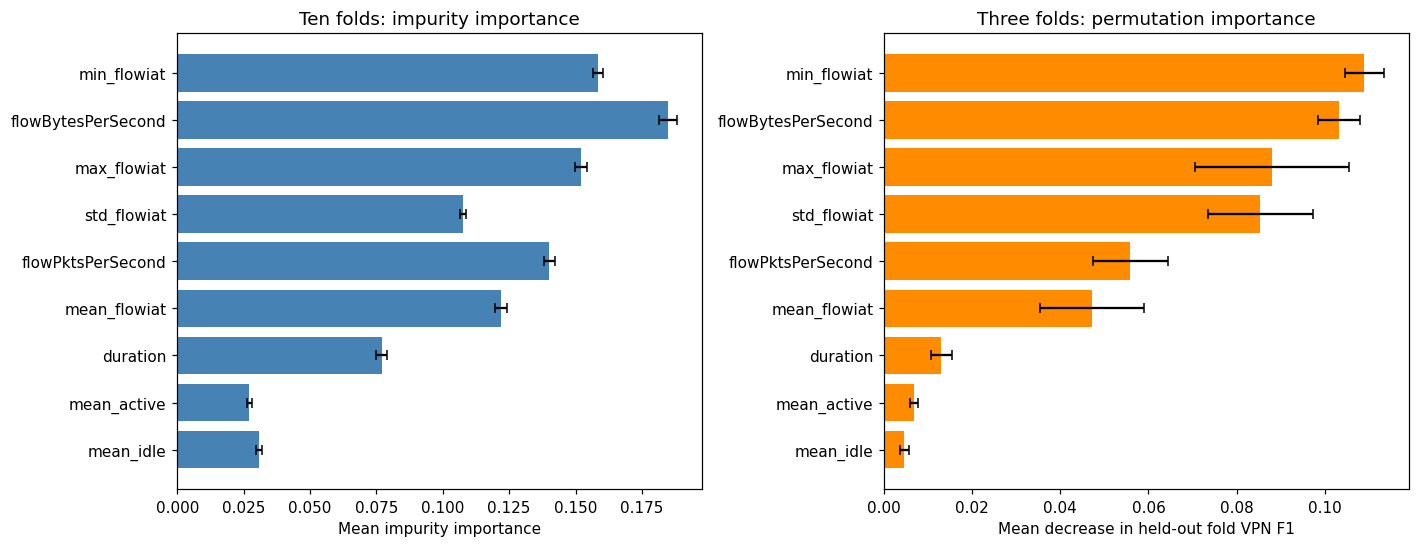

,Feature,MDI mean,MDI fold SD,MDI minimum,MDI maximum,Permutation mean F1 decrease,Permutation fold SD
8,mean_idle,0.0306,0.0011,0.0286,0.0321,0.0046,0.0011
7,mean_active,0.0271,0.0008,0.0258,0.0284,0.0068,0.0010
0,duration,0.0770,0.0021,0.0747,0.0808,0.0129,0.0024
5,mean_flowiat,0.1219,0.0022,0.1192,0.1264,0.0473,0.0118
1,flowPktsPerSecond,0.1401,0.0020,0.1359,0.1427,0.0559,0.0084
6,std_flowiat,0.1077,0.0012,0.1054,0.1099,0.0854,0.0119
4,max_flowiat,0.1521,0.0021,0.1482,0.1557,0.0881,0.0174
2,flowBytesPerSecond,0.1849,0.0033,0.1784,0.1892,0.1032,0.0047
3,min_flowiat,0.1585,0.0019,0.1551,0.1618,0.1090,0.0044


In [16]:
mdi=np.array(finalist_fold_scores.loc[finalist_fold_scores.Model==recommended_id,"MDI feature importance"].tolist())
importance_rows=[];permutation_rows=[]
for fold,(train_i,valid_i) in enumerate(cv3.split(X_train,y_train),1):
    fitted=clone(candidate_models[recommended_id]).fit(X_train.iloc[train_i],y_train.iloc[train_i])
    result=permutation_importance(fitted,X_train.iloc[valid_i],y_train.iloc[valid_i],scoring="f1",n_repeats=5,random_state=SEED,n_jobs=2)
    for j,feature in enumerate(FEATURES):
        permutation_rows.append({"Fold":fold,"Feature":feature,"Mean F1 decrease":result.importances_mean[j],"Repeat SD":result.importances_std[j],"Repeat decreases":result.importances[j].tolist()})
permutation_table=pd.DataFrame(permutation_rows)
for j,feature in enumerate(FEATURES):
    values=permutation_table.loc[permutation_table.Feature==feature,"Mean F1 decrease"]
    importance_rows.append({"Feature":feature,"MDI mean":mdi[:,j].mean(),"MDI fold SD":mdi[:,j].std(),"MDI minimum":mdi[:,j].min(),"MDI maximum":mdi[:,j].max(),"Permutation mean F1 decrease":values.mean(),"Permutation fold SD":values.std(ddof=0)})
importance_table=pd.DataFrame(importance_rows).sort_values("Permutation mean F1 decrease")
fig,axes=plt.subplots(1,2,figsize=(13,5.1),num="feature_importance")
axes[0].barh(importance_table.Feature,importance_table["MDI mean"],xerr=importance_table["MDI fold SD"],color="steelblue",capsize=3)
axes[0].set(xlabel="Mean impurity importance",title="Ten folds: impurity importance")
axes[1].barh(importance_table.Feature,importance_table["Permutation mean F1 decrease"],xerr=importance_table["Permutation fold SD"],color="darkorange",capsize=3)
axes[1].set(xlabel="Mean decrease in held-out fold VPN F1",title="Three folds: permutation importance")
plt.tight_layout();plt.show()
display(importance_table.round(4))
importance_table.to_csv(OUT/"feature_importance.csv",index=False);permutation_table.to_csv(OUT/"permutation_fold_scores.csv",index=False)

## Part 10 — Final recommendation
The recommendation below is the practical compromise from the disclosed exploratory criterion C. We also retain the model with the highest observed validation F1. Neither choice is claimed to dominate on every objective. A lower paired gap does not establish better predictive generalization.

Target ranges are descriptive checks after freezing, not selection filters. The full comparison includes all three algorithms and the four forest references. The recommended row may repeat a reference configuration if no local candidate offers a preferred trade-off.

### Saved-run recommendation
**Recommended practical compromise: RF-206**, with 200 entropy trees, maximum depth 14, leaf minimum 4, split minimum 10, five features per split and bootstrap fraction 0.70. Its full-training accuracy is 93.76%, full-training F1 is 0.9406, ten-fold F1 is 0.8938 and paired F1 gap is 0.0467. None of the new finalists replaces it under exploratory C. Original remains the highest observed validation-F1 option.

RF-206 averages about 372 leaves per tree in CV fits versus 1,147 for Original. It has twice as many trees, so total mean forest node count falls by about 35.1%. Its ten-fold F1 SD is 0.0087 versus Original's 0.0072. The recommendation reduces the observed fit gap while retaining a reasonably close score, but does not eliminate overfitting or establish superior external generalization. The desired training and validation ranges were not reached, and an independent test score remains unavailable.


In [17]:
print("Recommended practical compromise:",recommended_id)
print("Highest observed validation F1:",highest_validation_id)
print("Historical .005 rule applied to current finalists:",historical_rule_id)
print("Exact recommended settings:",json.dumps(selected_rf_params,indent=2))
display(required_comparison[["Model","Training accuracy","Training VPN F1","CV training accuracy","CV training F1","CV F1 mean","CV F1 std","CV F1 gap","CV accuracy","CV VPN precision","CV VPN recall","CV folds"]].round(5))
target_table=pd.DataFrame([
    {"Metric":"Full-training accuracy","Aspirational range":"92–93%","Actual":best_c["Training accuracy"],"Reached":bool(.92<=best_c["Training accuracy"]<=.93)},
    {"Metric":"Ten-fold validation VPN F1","Aspirational range":"0.91–0.92","Actual":best_c["CV F1 mean"],"Reached":bool(.91<=best_c["CV F1 mean"]<=.92)},
    {"Metric":"Independent test accuracy","Aspirational range":"91–92%","Actual":None,"Reached":"Unavailable"}])
display(target_table)

Recommended practical compromise: RF-206
Highest observed validation F1: Original Random Forest
Historical .005 rule applied to current finalists: Original Random Forest
Exact recommended settings: {
  "bootstrap": true,
  "ccp_alpha": 0.0,
  "class_weight": null,
  "criterion": "entropy",
  "max_depth": 14,
  "max_features": 5,
  "max_leaf_nodes": null,
  "max_samples": 0.7,
  "min_impurity_decrease": 0.0,
  "min_samples_leaf": 4,
  "min_samples_split": 10,
  "min_weight_fraction_leaf": 0.0,
  "monotonic_cst": null,
  "n_estimators": 200,
  "n_jobs": null,
  "oob_score": false,
  "random_state": 42,
  "verbose": 0,
  "warm_start": false
}


,Model,Training accuracy,Training VPN F1,CV training accuracy,CV training F1,CV F1 mean,CV F1 std,CV F1 gap,CV accuracy,CV VPN precision,CV VPN recall,CV folds
0,DummyClassifier,0.51839,0.68282,0.51839,0.68282,0.68282,0.00025,0.00000,0.51839,0.51839,1.00000,10
1,SGDClassifier,0.58931,0.64198,0.59140,0.63612,0.63689,0.03255,-0.00078,0.59216,0.59065,0.69395,10
2,Original Random Forest,0.99993,0.99993,1.00000,1.00000,0.90161,0.00719,0.09839,0.89717,0.89468,0.90880,10
3,Previous Tuned Random Forest,0.96732,0.96882,0.96843,0.96987,0.89655,0.00899,0.07332,0.89084,0.88123,0.91256,10
4,RF-206,0.93763,0.94062,0.93749,0.94052,0.89382,0.00869,0.04669,0.88778,0.87719,0.91122,10
5,RF-210,0.92568,0.92922,0.92449,0.92824,0.89045,0.00750,0.03779,0.88417,0.87357,0.90813,10
6,Final Recommended Random Forest,0.93763,0.94062,0.93749,0.94052,0.89382,0.00869,0.04669,0.88778,0.87719,0.91122,10


,Metric,Aspirational range,Actual,Reached
0,Full-training accuracy,92–93%,0.937635,False
1,Ten-fold validation VPN F1,0.91–0.92,0.893824,False
2,Independent test accuracy,91–92%,NaN,Unavailable


## Part 11 — Frozen model evaluation and limitations
- Repeated screening and selection use the same training partition. Ten-fold values are selected comparison estimates and may be optimistic. The conditional nested check does not undo earlier choices informed by the full training set.
- The historical test partition was inspected in earlier revisions. The already-selected RF-206 is now evaluated on this same partition without changing its parameters or prediction rule. These measurements are labeled **Reused development-test evaluation — not an independent untouched test.** Original RF's results and confusion matrix remain historical records.
- Conflicting-label removal before splitting makes dataset construction label-dependent. Pipelines prevent learned median/scaling leakage within CV, but cannot undo this earlier filtering.
- Without capture/session identifiers we cannot exclude related flows across folds. Close numerical neighbors are a warning to investigate, not proof of a shared session.
- The pinned public mirror has not been independently matched against the official archive. Traffic from 2016 may not represent current networks. The local search is bounded and does not rule out better untested settings.
- We did not obtain and validate an independent dataset compatible with the frozen nine-feature pipeline. [CICDarknet2020](https://www.unb.ca/cic/datasets/darknet2020.html) reuses ISCXVPN2016, so it would not supply independent VPN evidence. [MIT VNAT](https://www.ll.mit.edu/r-d/datasets/vpnnonvpn-network-application-traffic-dataset-vnat) is a possible independent source, but its provided small feature file uses a different representation. Compatible extraction and unit checks are future work.

Fold SDs and paired differences are descriptive. The folds share training data; they are not independent replicate datasets. No statistical superiority or elimination of overfitting is claimed.

The next cell fits the frozen pipeline on all 14,383 training rows, predicts the 3,596 existing test rows, and verifies accuracy, VPN precision, recall and F1 against the confusion matrix. ROC-AUC uses VPN probabilities rather than predicted class labels. Both matrices use true labels as rows and predicted labels as columns, ordered NonVPN then VPN. The unchanged `predict` method resolves probability ties in class order. The test measurements cannot alter the earlier selection.


Reused development-test evaluation — not an independent untouched test.


Model,Original Random Forest,Tuned Random Forest (RF-206)
Training Accuracy,0.999930,0.937635
Training VPN F1,0.999933,0.940616
Mean 10-fold Validation VPN F1,0.901607,0.893824
Train–Validation F1 Gap,0.098393,0.046692
Test Accuracy,0.906563,0.893215
Test VPN precision,0.900839,0.879098
Test VPN recall,0.921137,0.920601
Test VPN F1,0.910875,0.899371
Test ROC-AUC,0.967685,0.963942


Confusion matrices: rows = true [NonVPN, VPN], columns = predicted [NonVPN, VPN]
Original Random Forest (historical): [[1543, 189], [147, 1717]]
Tuned Random Forest (RF-206): [[1496, 236], [148, 1716]]


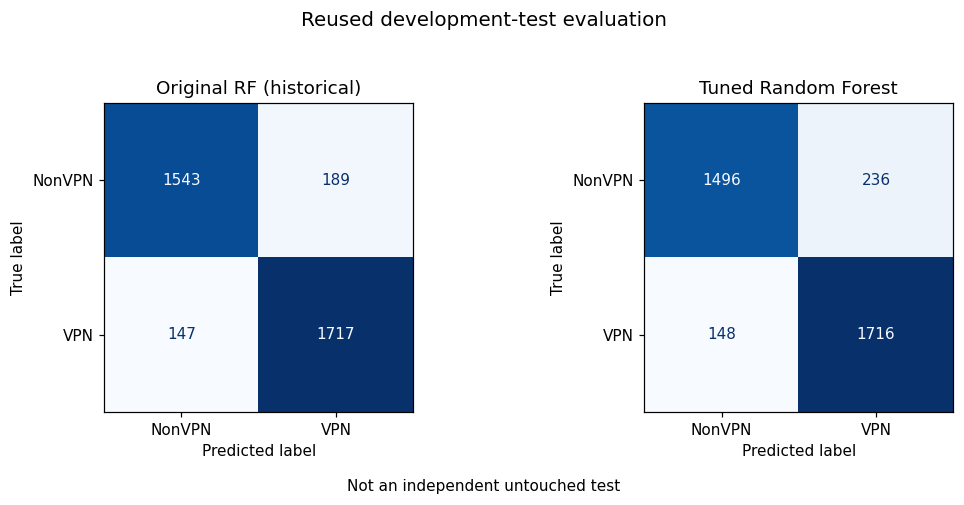

RF-206 remains frozen. Independent evaluation is still unavailable.


In [18]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay)
from datetime import datetime, timezone

EVALUATION_STATUS = "Reused development-test evaluation — not an independent untouched test."
# This model was selected before this evaluation update. Test scores cannot change it.
FROZEN_RF206 = {
    "n_estimators": 200, "criterion": "entropy", "max_depth": 14,
    "min_samples_leaf": 4, "min_samples_split": 10, "max_features": 5,
    "max_samples": 0.7, "bootstrap": True, "random_state": 42,
    "ccp_alpha": 0.0, "class_weight": None, "max_leaf_nodes": None,
    "min_impurity_decrease": 0.0, "min_weight_fraction_leaf": 0.0,
    "monotonic_cst": None, "n_jobs": None, "oob_score": False,
    "verbose": 0, "warm_start": False
}
assert recommended_id == "RF-206"
assert selected_rf_params == FROZEN_RF206
selection_before_test = json.dumps(final_selection, sort_keys=True)
tuned_test_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(**FROZEN_RF206))
])
# Fit both the imputer and forest only on the complete existing training partition.
tuned_test_pipeline.fit(X_train, y_train)
training_medians = X_train.median().to_numpy()
np.testing.assert_allclose(tuned_test_pipeline.named_steps["imputer"].statistics_,
                           training_medians, rtol=1e-12, atol=1e-12)
assert tuned_test_pipeline.named_steps["model"].get_params() == FROZEN_RF206

# Keep the classifier's normal predict rule. There is no threshold search.
tuned_test_prediction = tuned_test_pipeline.predict(X_test)
positive_column = list(tuned_test_pipeline.classes_).index(1)
tuned_test_probability = tuned_test_pipeline.predict_proba(X_test)[:, positive_column]
tuned_test_cm = confusion_matrix(y_test, tuned_test_prediction, labels=[0, 1])
tn, fp, fn, tp = (int(v) for v in tuned_test_cm.ravel())
tuned_test_metrics = {
    "Accuracy": float(accuracy_score(y_test, tuned_test_prediction)),
    "VPN precision": float(precision_score(y_test, tuned_test_prediction, pos_label=1, zero_division=0)),
    "VPN recall": float(recall_score(y_test, tuned_test_prediction, pos_label=1, zero_division=0)),
    "VPN F1": float(f1_score(y_test, tuned_test_prediction, pos_label=1, zero_division=0)),
    "ROC-AUC": float(roc_auc_score(y_test, tuned_test_probability))
}
matrix_metrics = {
    "Accuracy": (tn + tp) / (tn + fp + fn + tp),
    "VPN precision": tp / (tp + fp),
    "VPN recall": tp / (tp + fn),
    "VPN F1": 2 * tp / (2 * tp + fp + fn)
}
for metric, value in matrix_metrics.items():
    assert np.isclose(tuned_test_metrics[metric], value, rtol=0, atol=1e-15), metric
assert int(tuned_test_cm.sum()) == len(X_test) == 3596
assert tuned_test_cm.sum(axis=1).tolist() == y_test.value_counts().sort_index().tolist()

# Retain Original RF's recorded results. Do not refit or rescore it on the test set.
original_test_metrics = {
    "Accuracy": 0.9065628476084538, "VPN precision": 0.9008394543546695,
    "VPN recall": 0.921137339055794, "VPN F1": 0.9108753315649868,
    "ROC-AUC": 0.9676854017781918
}
original_test_cm = np.array([[1543, 189], [147, 1717]])
otn, ofp, ofn, otp = (int(v) for v in original_test_cm.ravel())
for metric, value in {
    "Accuracy": (otn + otp) / original_test_cm.sum(),
    "VPN precision": otp / (otp + ofp),
    "VPN recall": otp / (otp + ofn),
    "VPN F1": 2 * otp / (2 * otp + ofp + ofn)
}.items():
    assert np.isclose(original_test_metrics[metric], value, rtol=0, atol=1e-15)
assert original_test_cm.sum(axis=1).tolist() == tuned_test_cm.sum(axis=1).tolist()

historical_test_table = pd.DataFrame([{
    "Model": "Original Random Forest",
    "Evaluation status": "Historical result on the reused development-test partition",
    **original_test_metrics
}])
test_comparison_table = pd.DataFrame([
    historical_test_table.iloc[0].to_dict(),
    {"Model": "Tuned Random Forest (RF-206)", "Evaluation status": EVALUATION_STATUS,
     **tuned_test_metrics}
])
final_test_comparison_rows = []
for technical_name, display_name, metrics in [
    ("Original Random Forest", "Original Random Forest", original_test_metrics),
    ("RF-206", "Tuned Random Forest (RF-206)", tuned_test_metrics)
]:
    prior = required_comparison.loc[required_comparison.Model == technical_name].iloc[0]
    final_test_comparison_rows.append({
        "Model": display_name,
        "Training Accuracy": float(prior["Training accuracy"]),
        "Training VPN F1": float(prior["Training VPN F1"]),
        "Mean 10-fold Validation VPN F1": float(prior["CV F1 mean"]),
        "Train–Validation F1 Gap": float(prior["CV F1 gap"]),
        **{"Test " + metric: value for metric, value in metrics.items()}
    })
final_test_comparison_table = pd.DataFrame(final_test_comparison_rows)
print(EVALUATION_STATUS)
display(final_test_comparison_table.set_index("Model").T)
print("Confusion matrices: rows = true [NonVPN, VPN], columns = predicted [NonVPN, VPN]")
print("Original Random Forest (historical):", original_test_cm.tolist())
print("Tuned Random Forest (RF-206):", tuned_test_cm.tolist())
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), num="reused_test_confusion_matrices")
for ax, title, matrix in [
    (axes[0], "Original RF (historical)", original_test_cm),
    (axes[1], "Tuned Random Forest", tuned_test_cm)
]:
    ConfusionMatrixDisplay(matrix, display_labels=["NonVPN", "VPN"]).plot(
        ax=ax, colorbar=False, cmap="Blues", values_format="d")
    ax.set_title(title)
fig.suptitle("Reused development-test evaluation", fontsize=13)
fig.text(0.5, 0.01, "Not an independent untouched test", ha="center", fontsize=10)
plt.tight_layout(rect=[0, 0.04, 1, 0.95])
plt.show()
predictions_table = pd.DataFrame({
    "source_row_index": X_test.index.to_numpy(), "true_label": y_test.to_numpy(),
    "predicted_label": tuned_test_prediction, "vpn_probability": tuned_test_probability
})
predictions_path = OUT / "rf206_reused_test_predictions.csv"
predictions_table.to_csv(predictions_path, index=False)
assert json.dumps(final_selection, sort_keys=True) == selection_before_test
assert recommended_id == "RF-206" and selected_rf_params == FROZEN_RF206
reused_test_evaluation = {
    "evaluated_utc": datetime.now(timezone.utc).isoformat(),
    "evaluation_status": EVALUATION_STATUS,
    "model": "Tuned Random Forest (RF-206)", "selected_id": "RF-206",
    "parameters": FROZEN_RF206, "positive_class": 1,
    "classes": tuned_test_pipeline.classes_.tolist(),
    "prediction_rule": "RandomForestClassifier.predict; no threshold adjustment",
    "train_rows": len(X_train), "test_rows": len(X_test), "features": features,
    "dataset_sha256": expected_hash, "test_index_sha256": split_hash,
    "training_imputer_medians": training_medians.tolist(),
    "imputer_training_only_verified": True,
    "metrics": tuned_test_metrics, "confusion_matrix": tuned_test_cm.tolist(),
    "matrix_layout": "rows=true [NonVPN, VPN]; columns=predicted [NonVPN, VPN]",
    "confusion_matrix_metrics_verified": True,
    "historical_original_metrics": original_test_metrics,
    "historical_original_confusion_matrix": original_test_cm.tolist(),
    "historical_original_source": "Preserved systematic results.json, confusion_matrices['Original RF']",
    "selection_unchanged": True, "new_hyperparameter_candidates": 0,
    "predictions_sha256": hashlib.sha256(predictions_path.read_bytes()).hexdigest(),
    "comparison": final_test_comparison_rows
}
(OUT / "reused_test_evaluation.json").write_text(
    json.dumps(reused_test_evaluation, indent=2, allow_nan=False) + "\n")
test_comparison_table.to_csv(OUT / "reused_test_metrics.csv", index=False)
final_test_comparison_table.to_csv(OUT / "final_train_validation_test_comparison.csv", index=False)
print("RF-206 remains frozen. Independent evaluation is still unavailable.")


## Part 12 — Conclusion and reproducible exports
The executed tables show whether the local search changes the practical recommendation, how much validation F1 is exchanged for a smaller gap, and which targets remain unmet. The strongest predictive score and the preferred complexity trade-off are separate conclusions. Fresh session-separated traffic is needed before making a stronger external generalization claim.

**Assistance:** OpenAI Codex supported explanations, research, code generation, debugging, local execution, figures and drafts. The students are responsible for checking the work and understanding every step. Individual contributions should describe the work actually performed.

### References
- [Draper-Gil et al., Characterization of Encrypted and VPN Traffic Using Time-related Features (2016)](https://doi.org/10.5220/0005740704070414)
- [CIC official ISCXVPN2016 description](https://www.unb.ca/cic/datasets/vpn.html)
- [Exact pinned ARFF mirror](https://github.com/shafwanur/thd-ss25-ml-project/blob/b4488cf1022157a319d9ccdfa36f86cb940e2b80/data/15s.arff)
- [Original ISCXFlowMeter duration calculation](https://github.com/ahlashkari/ISCXFlowMeter/blob/f3287486f114350b0b79dcfcf1050bc6a85190cf/src/main/java/iscx/cs/unb/ca/ifm/data/BasicFlow.java#L168-L172)
- [Scikit-learn cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html), [nested CV example](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html) and [permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html)

### What this revision established
All four reference forests reproduced exactly. Twenty genuinely new local settings were screened, and six genuinely new finalists joined historical comparisons. The search found no new preferred compromise. RF-206 remains a practical recommendation only under the explicitly exploratory 0.010 rule; the historical 0.005 rule still retains Original RF.

The conditional nested check has mean outer F1 0.884643. It checks a different, three-fold local selection procedure and retains limitations from the historical center choice and global cleaning. It is not an independent test score for RF-206. This final evaluation update adds predictions for the frozen RF-206 on the existing partition. It does not add tuning candidates or change the recommendation. **Reused development-test evaluation — not an independent untouched test.** Fresh captures with compatible feature extraction and session separation are the next evidence needed.

### Frozen model reused-test findings
RF-206 remains the selected **Tuned Random Forest**. Its reused-test accuracy is **0.8932146829810901**
(89.321468%) and VPN F1 is **0.8993710691823900**.
VPN precision is 0.879098361, recall is 0.920600858,
and ROC-AUC is 0.963941807. The confusion matrix is `[[1496, 236], [148, 1716]]`,
with true classes as rows and predictions as columns, both ordered NonVPN, VPN.

**Reused development-test evaluation — not an independent untouched test.**
The F1 of 0.8994 is broadly consistent with the prior ten-fold mean of 0.8938.
Original RF's historical F1 is 0.9109 and accuracy is 90.66%, both higher than Tuned Random Forest.
The tuned model makes 47 more false VPN alarms and one more missed VPN flow on this partition.
This supports the earlier observed score trade-off; the smaller CV gap does not imply higher predictive accuracy.
We preserve RF-206, its default prediction rule and all earlier CV results. No test score is used for optimization.
An unbiased independent estimate still requires genuinely new data.


### Exact settings and experiment exports
The tables below preserve every estimator parameter, fold score, selection criterion and measured structural diagnostic. Outputs are written in this notebook's output folder for inspection; they are never loaded as inputs. The data, labels, cleaning, original split, seed and feature list remain unchanged.

Mean-decrease-in-impurity feature importance is descriptive. It can favor features with many candidate split points, and correlated timing measurements can share or shift importance. Fold variation in importance is not evidence that a feature is causal. It is not used to remove features or select the model.

In [19]:
def json_safe(value):
    if isinstance(value,dict):return {str(key):json_safe(item) for key,item in value.items()}
    if isinstance(value,(list,tuple)):return [json_safe(item) for item in value]
    if isinstance(value,np.ndarray):return json_safe(value.tolist())
    if isinstance(value,np.generic):return json_safe(value.item())
    if isinstance(value,float) and not np.isfinite(value):return None
    return value

model_parameters={name:pipeline.named_steps["model"].get_params() for name,pipeline in candidate_models.items()}
model_parameters["Final Recommended Random Forest"]=selected_rf_params
preprocessing_parameters={"imputer":SimpleImputer(strategy="median").get_params(),
    "SGD scaler":StandardScaler().get_params(),"missing_value_marker":"NaN"}
tables_to_save={"reference_comparison":reference_table,"reference_reproduction":reference_reproduction,
    "reference_fold_scores":reference_fold_scores,"oat_screening":screening_table,
    "oat_screening_fold_scores":screening_fold_scores,"finalist_comparison":finalists_table,
    "finalist_fold_scores":finalist_fold_scores,"required_comparison":required_comparison,
    "selection_criteria":criterion_results,"pareto_candidates":pareto_table,
    "paired_fold_differences":paired_differences,"paired_difference_summary":paired_summary,
    "nested_outer_results":nested_table,"nested_inner_results":nested_inner_table,
    "nested_inner_fold_scores":nested_fold_scores}
for filename,frame in tables_to_save.items():
    frame.to_csv(OUT/(filename+".csv"),index=False)
for filename,content in {"model_parameters":model_parameters,"preprocessing_parameters":preprocessing_parameters,
                         "final_selection":final_selection,"conditional_nested_summary":nested_summary}.items():
    (OUT/(filename+".json")).write_text(json.dumps(json_safe(content),indent=2,allow_nan=False)+chr(10))
display(required_comparison[["Model","Training accuracy","Training VPN F1","CV training F1","CV F1 mean",
    "CV F1 std","CV F1 gap","CV accuracy","CV VPN precision","CV VPN recall","CV folds"]].round(4))
print("All experimental exports saved to",OUT.resolve())

,Model,Training accuracy,Training VPN F1,CV training F1,CV F1 mean,CV F1 std,CV F1 gap,CV accuracy,CV VPN precision,CV VPN recall,CV folds
0,DummyClassifier,0.5184,0.6828,0.6828,0.6828,0.0003,0.0000,0.5184,0.5184,1.0000,10
1,SGDClassifier,0.5893,0.6420,0.6361,0.6369,0.0326,-0.0008,0.5922,0.5907,0.6939,10
2,Original Random Forest,0.9999,0.9999,1.0000,0.9016,0.0072,0.0984,0.8972,0.8947,0.9088,10
3,Previous Tuned Random Forest,0.9673,0.9688,0.9699,0.8965,0.0090,0.0733,0.8908,0.8812,0.9126,10
4,RF-206,0.9376,0.9406,0.9405,0.8938,0.0087,0.0467,0.8878,0.8772,0.9112,10
5,RF-210,0.9257,0.9292,0.9282,0.8904,0.0075,0.0378,0.8842,0.8736,0.9081,10
6,Final Recommended Random Forest,0.9376,0.9406,0.9405,0.8938,0.0087,0.0467,0.8878,0.8772,0.9112,10


All experimental exports saved to /Users/shucaybahmed/Documents/Codex/2026-09-13/jag-kommer-dela-med-dig-ett/work/final_evaluation/execution/advanced_results


In [20]:
full_counts,full_edges=np.histogram(duration_seconds,bins=30)
zoom_counts,zoom_edges=np.histogram(duration_seconds,bins=np.linspace(0,15,31))
results={"run_utc":datetime.now(timezone.utc).isoformat(),"environment":{"Python":sys.version.split()[0],**{name:importlib.metadata.version(name) for name in versions}},
    "counts":data_counts,"features":FEATURES,"data_sha256":expected_hash,"held_out_index_sha256":split_hash,
    "exact_input_overlap":exact_overlap,"reference_reproduction":reference_reproduction.to_dict("records"),
    "selection":final_selection,"criteria":criterion_results.to_dict("records"),"comparison":required_comparison.to_dict("records"),
    "finalists":finalists_table.to_dict("records"),"screening":screening_table.to_dict("records"),
    "paired_summary":paired_summary.to_dict("records"),"conditional_nested":nested_summary,
    "learning_curves":learning_curve_table.to_dict("records"),"validation_curves":validation_curve_table.to_dict("records"),
    "feature_importance":importance_table.to_dict("records"),"near_duplicate_audit":near_duplicate_table.to_dict("records"),
    "historical_test":historical_test_table.to_dict("records"),"targets":target_table.to_dict("records"),
    "correlation":correlation_table.to_dict(),"duration":{"unit":"seconds","outside_zoom":outside_zoom,"summary":duration_summary.to_dict(),"full_counts":full_counts,"full_edges":full_edges,"zoom_counts":zoom_counts,"zoom_edges":zoom_edges},
    "new_test_predictions":len(X_test),"new_test_prediction_batches":1,"reused_test_evaluation":reused_test_evaluation,"final_test_comparison":final_test_comparison_table.to_dict("records"),"historical_rule_note":"Previous .005 rule retained Original RF. C=.010 is explicitly post-hoc exploratory.",
    "class_medians":class_medians.to_dict(),"feature_summary":feature_summary.to_dict()}
(OUT/"results.json").write_text(json.dumps(json_safe(results),indent=2,allow_nan=False)+"\n")
target_table.to_csv(OUT/"target_check.csv",index=False)
historical_test_table.to_csv(OUT/"historical_test_context.csv",index=False)
print("Complete. Recommendation:",recommended_id,"; actual ten-fold VPN F1:",round(float(best_c["CV F1 mean"]),6))
print("Observed paired F1 gap:",round(float(best_c["CV F1 gap"]),6),"; independent test score unavailable.")
print("All tables and exact settings:",OUT.resolve())
print("Frozen RF-206 reused-test metrics:",tuned_test_metrics)
print(EVALUATION_STATUS)


Complete. Recommendation: RF-206 ; actual ten-fold VPN F1: 0.893824
Observed paired F1 gap: 0.046692 ; independent test score unavailable.
All tables and exact settings: /Users/shucaybahmed/Documents/Codex/2026-09-13/jag-kommer-dela-med-dig-ett/work/final_evaluation/execution/advanced_results
Frozen RF-206 reused-test metrics: {'Accuracy': 0.8932146829810901, 'VPN precision': 0.8790983606557377, 'VPN recall': 0.9206008583690987, 'VPN F1': 0.89937106918239, 'ROC-AUC': 0.9639418073328113}
Reused development-test evaluation — not an independent untouched test.
